# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['R',
 'dPhi_r_b',
 'MT2',
 'cos_theta_r1',
 'M_TR_2',
 'M_Delta_R',
 'MET_rel',
 'S_R',
 'M_R',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,1.0,0.853325,-0.961783,-1.487277,0.678190,0.493580,1.647969,1.843867,0.276954,1.025105,-1.486535,0.892879,1.684429,1.674084,3.366298,1.046707,2.646649,1.389226,0.364599
4999996,0.0,0.951581,0.139370,1.436884,0.880440,-0.351948,-0.740852,0.290863,-0.732360,0.001360,0.257738,0.802871,0.545319,0.602730,0.002998,0.748959,0.401166,0.443471,0.239953
4999997,0.0,0.840389,1.419162,-1.218766,1.195631,1.695645,0.663756,0.490888,-0.509186,0.704289,0.045744,0.825015,0.723530,0.778236,0.752942,0.838953,0.614048,1.210595,0.026692
4999998,1.0,1.784218,-0.833565,-0.560091,0.953342,-0.688969,-1.428233,2.660703,-0.861344,2.116892,2.906151,1.232334,0.952444,0.685846,0.000000,0.781874,0.676003,1.197807,0.093689


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


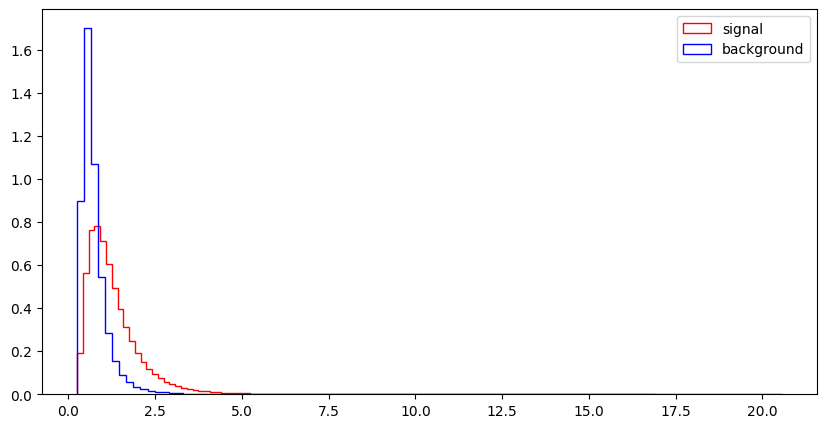

l_1_eta


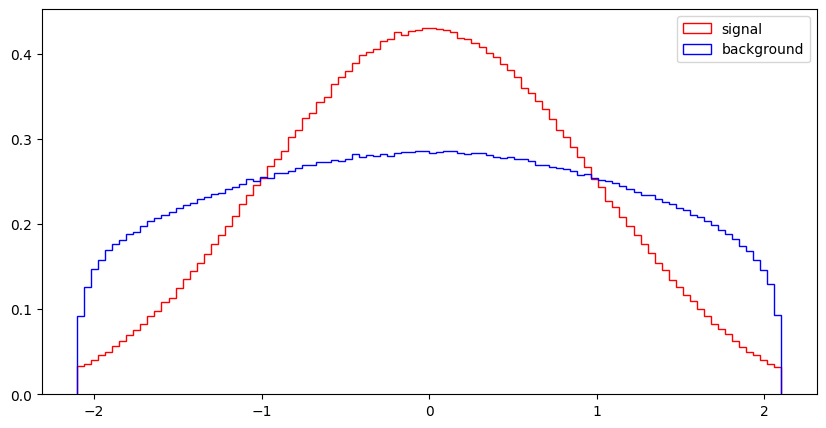

l_1_phi


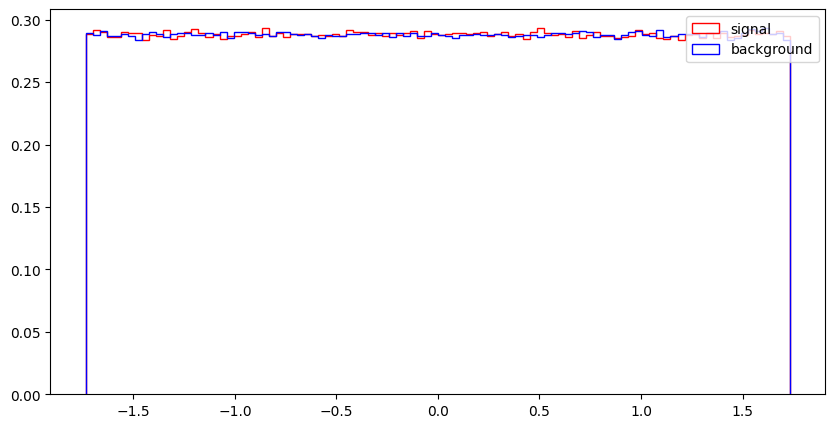

l_2_pT


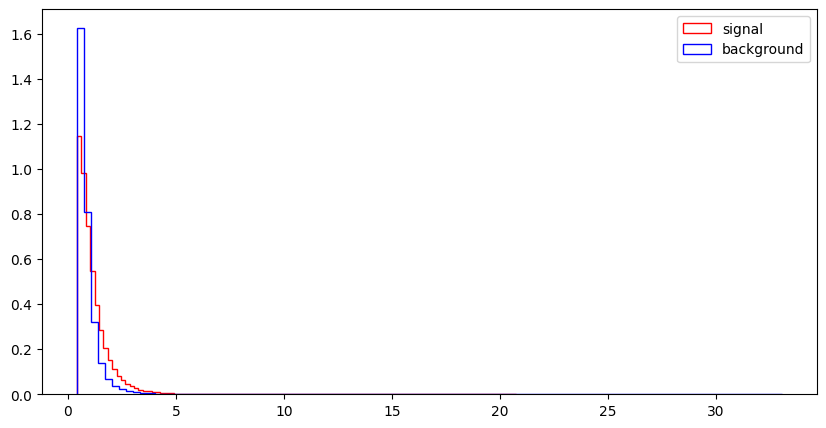

l_2_eta


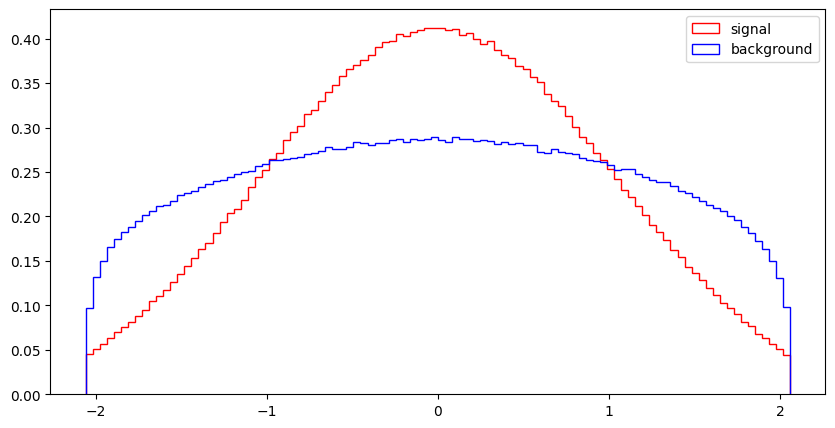

l_2_phi


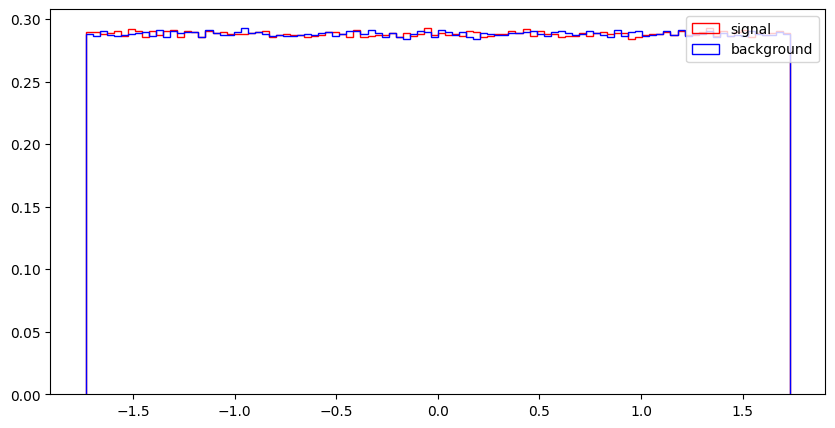

MET


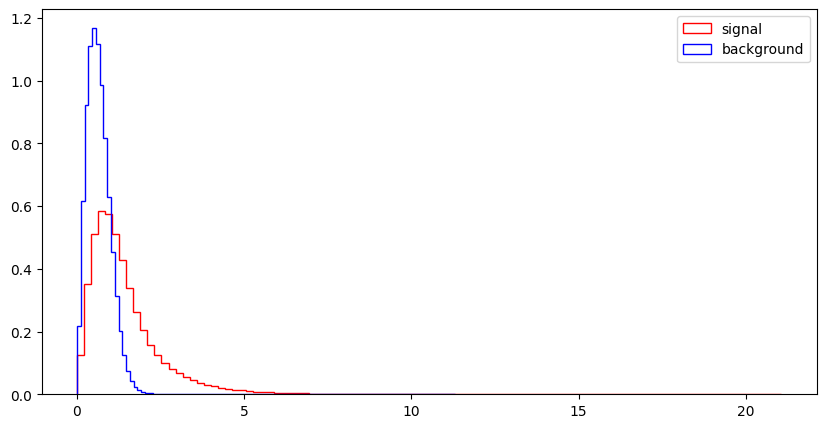

MET_phi


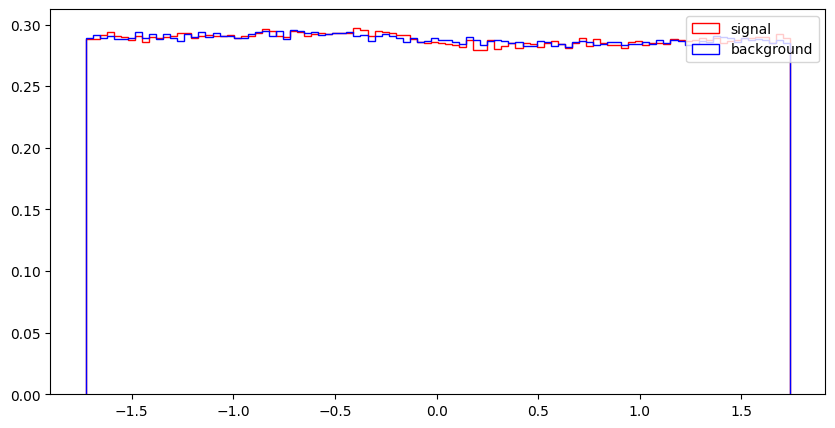

MET_rel


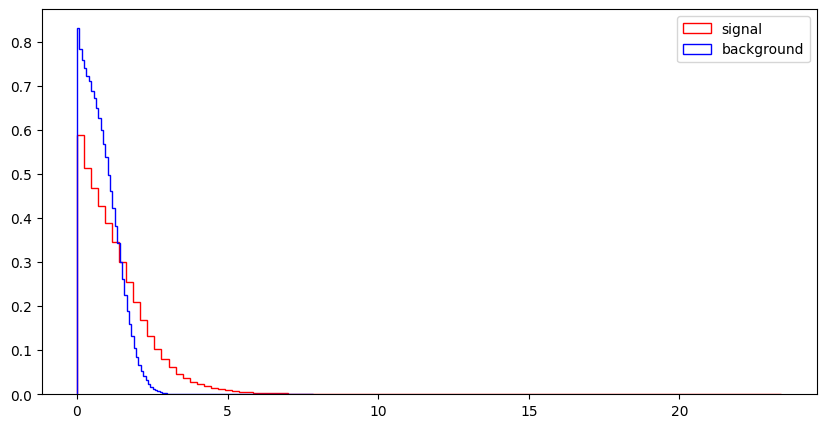

axial_MET


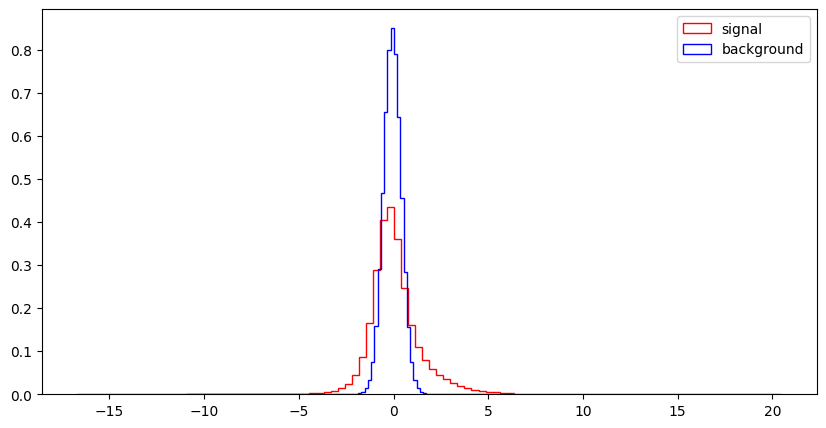

M_R


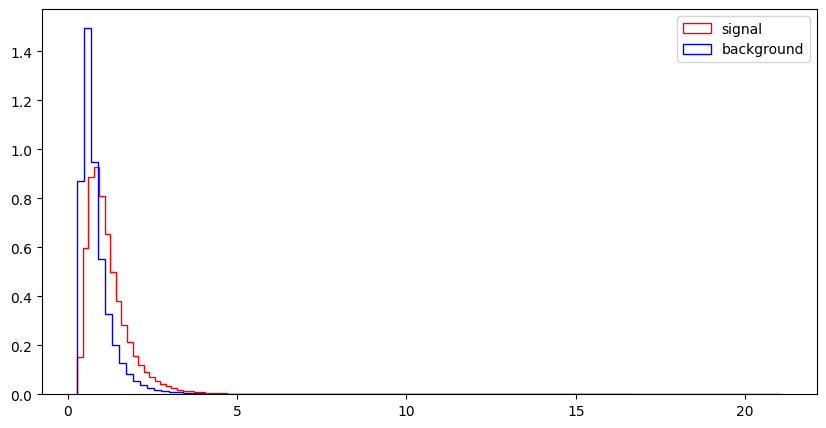

M_TR_2


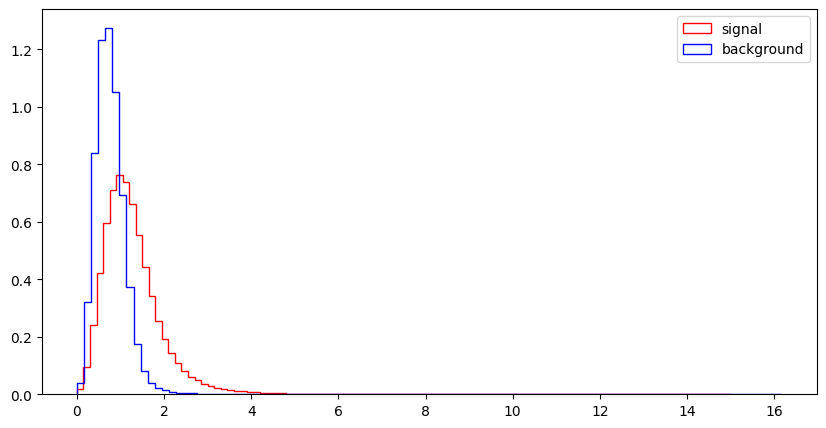

R


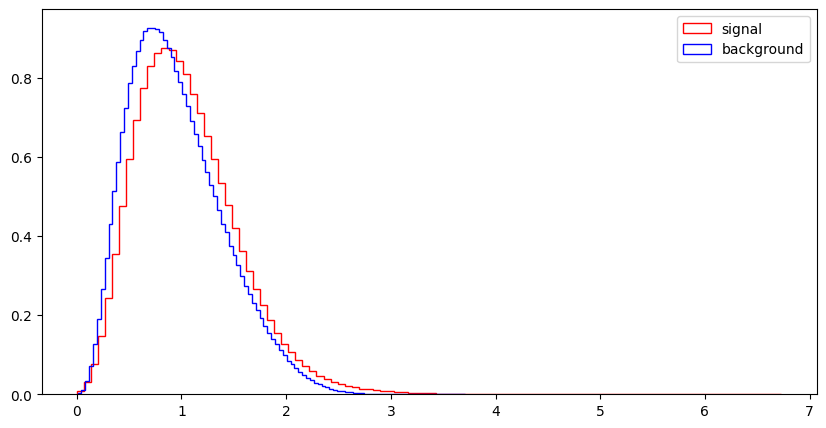

MT2


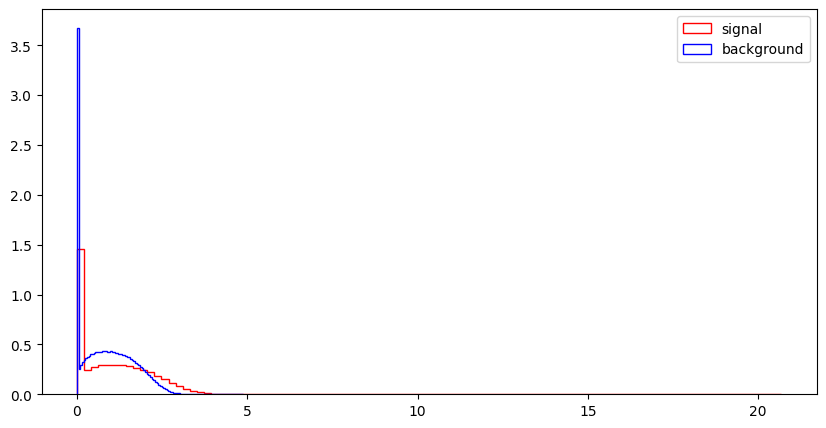

S_R


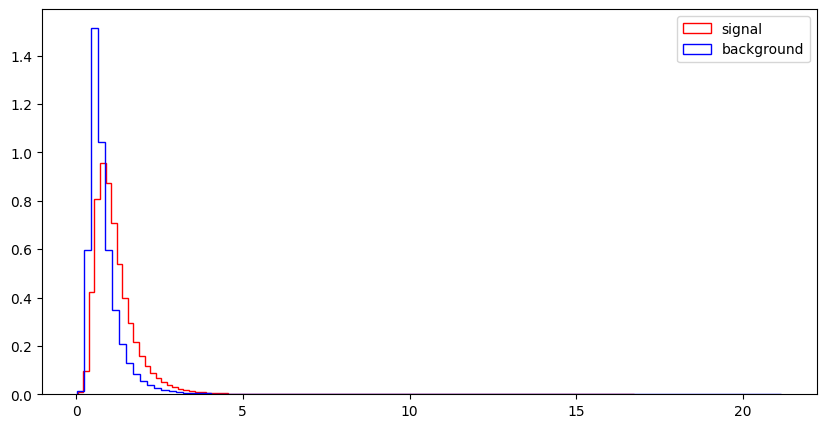

M_Delta_R


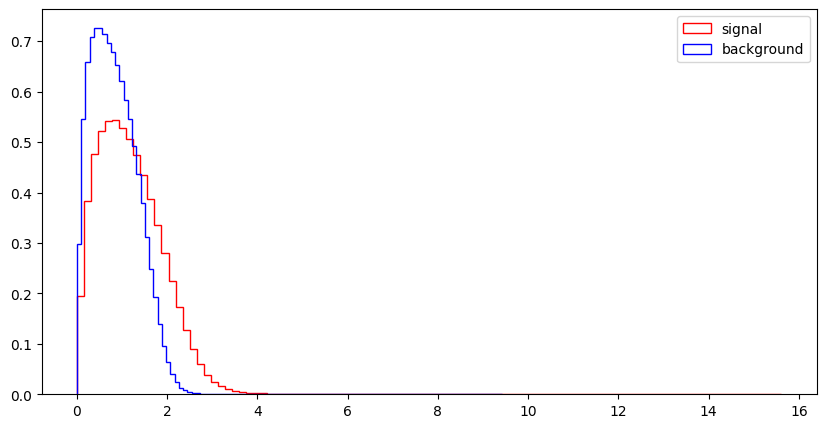

dPhi_r_b


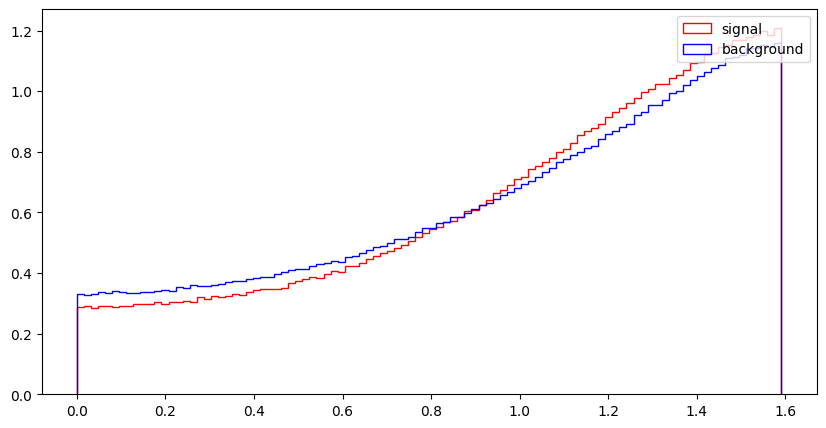

cos_theta_r1


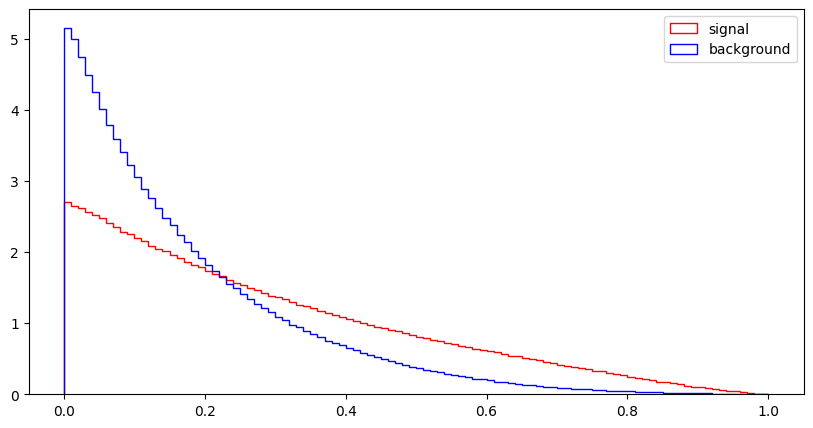

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [1]:
#2
import os
import gzip
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not os.path.exists("SUSY-small.csv"):
    if not os.path.exists("SUSY.csv.gz"):
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz"
        print("Downloading SUSY.csv.gz (large file)...")
        urllib.request.urlretrieve(url, "SUSY.csv.gz")

    print("Extracting the first 500000 rows...")
    with gzip.open("SUSY.csv.gz", "rt") as source:
        with open("SUSY-small.csv", "w") as output:
            for i in range(500000):
                line = source.readline()
                if line == "":
                    break
                output.write(line)

print("Small dataset ready:", os.path.getsize("SUSY-small.csv"), "bytes")

Extracting the first 500000 rows...
Small dataset ready: 239027366 bytes


In [2]:
#2
VarNames = ["signal", "l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames = ["l_1_pT", "l_1_eta", "l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames = [name for name in VarNames[1:] if name not in RawNames]

df = pd.read_csv("SUSY-small.csv", names=VarNames)
df_sig = df[df["signal"] == 1]
df_bkg = df[df["signal"] == 0]

print("Rows:", len(df))
print("Signal events:", len(df_sig))
print("Background events:", len(df_bkg))
print("Low-level features:", RawNames)
print("High-level features:", FeatureNames)
display(df.head())

Rows: 500000
Signal events: 229245
Background events: 270755
Low-level features: ['l_1_pT', 'l_1_eta', 'l_1_phi', 'l_2_pT', 'l_2_eta', 'l_2_phi', 'MET', 'MET_phi']
High-level features: ['MET_rel', 'axial_MET', 'M_R', 'M_TR_2', 'R', 'MT2', 'S_R', 'M_Delta_R', 'dPhi_r_b', 'cos_theta_r1']


,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


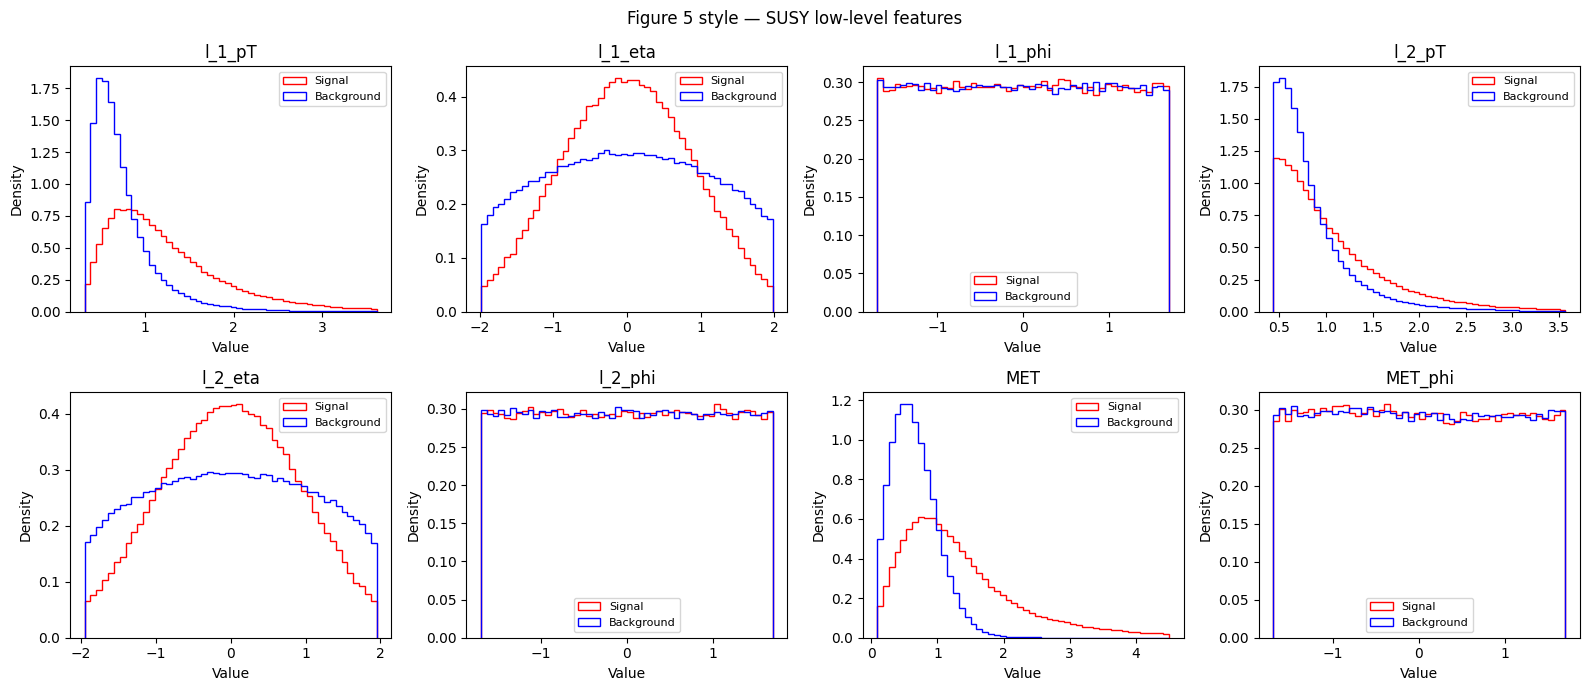

In [3]:
#3
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i in range(len(RawNames)):
    name = RawNames[i]
    ax = axes.flat[i]
    low = df[name].quantile(0.01)
    high = df[name].quantile(0.99)
    ax.hist(df_sig[name], bins=50, range=(low, high), density=True, histtype="step", label="Signal", color="red")
    ax.hist(df_bkg[name], bins=50, range=(low, high), density=True, histtype="step", label="Background", color="blue")
    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

fig.suptitle("Figure 5 style — SUSY low-level features")
plt.tight_layout()
plt.show()

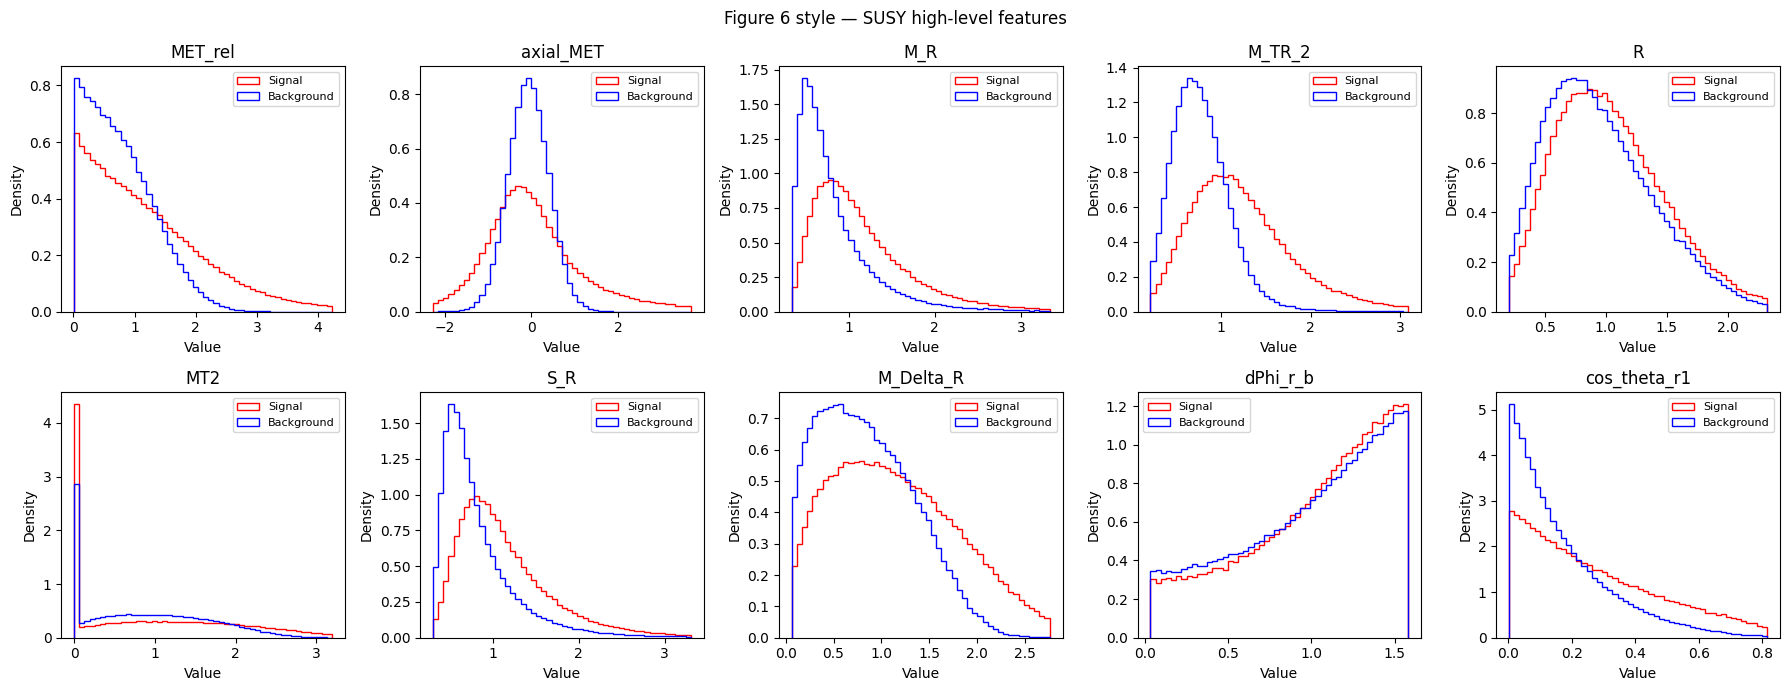

In [4]:
#3
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i in range(len(FeatureNames)):
    name = FeatureNames[i]
    ax = axes.flat[i]
    low = df[name].quantile(0.01)
    high = df[name].quantile(0.99)
    ax.hist(df_sig[name], bins=50, range=(low, high), density=True, histtype="step", label="Signal", color="red")
    ax.hist(df_bkg[name], bins=50, range=(low, high), density=True, histtype="step", label="Background", color="blue")
    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

fig.suptitle("Figure 6 style — SUSY high-level features")
plt.tight_layout()
plt.show()

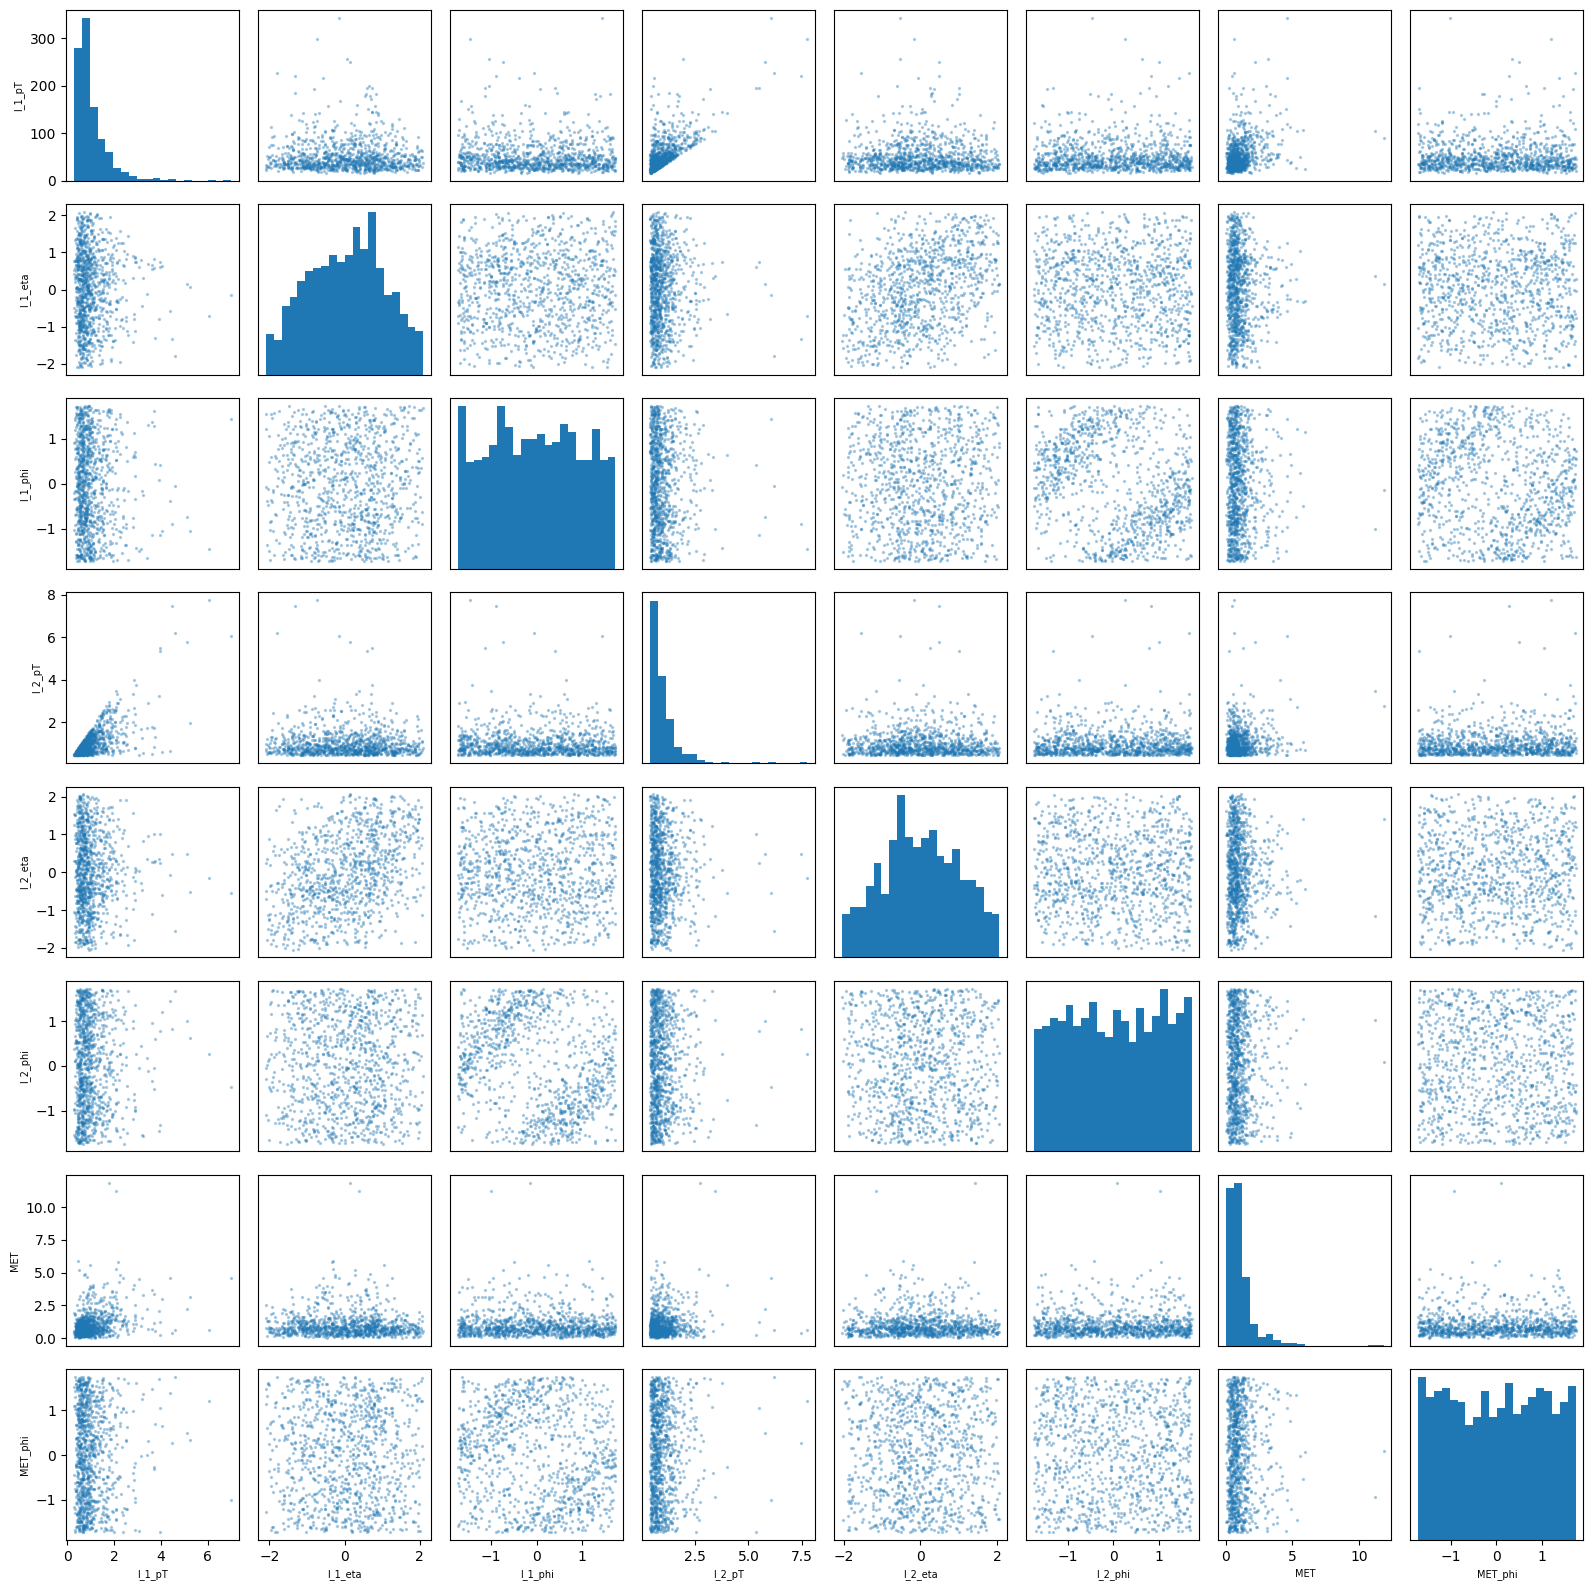

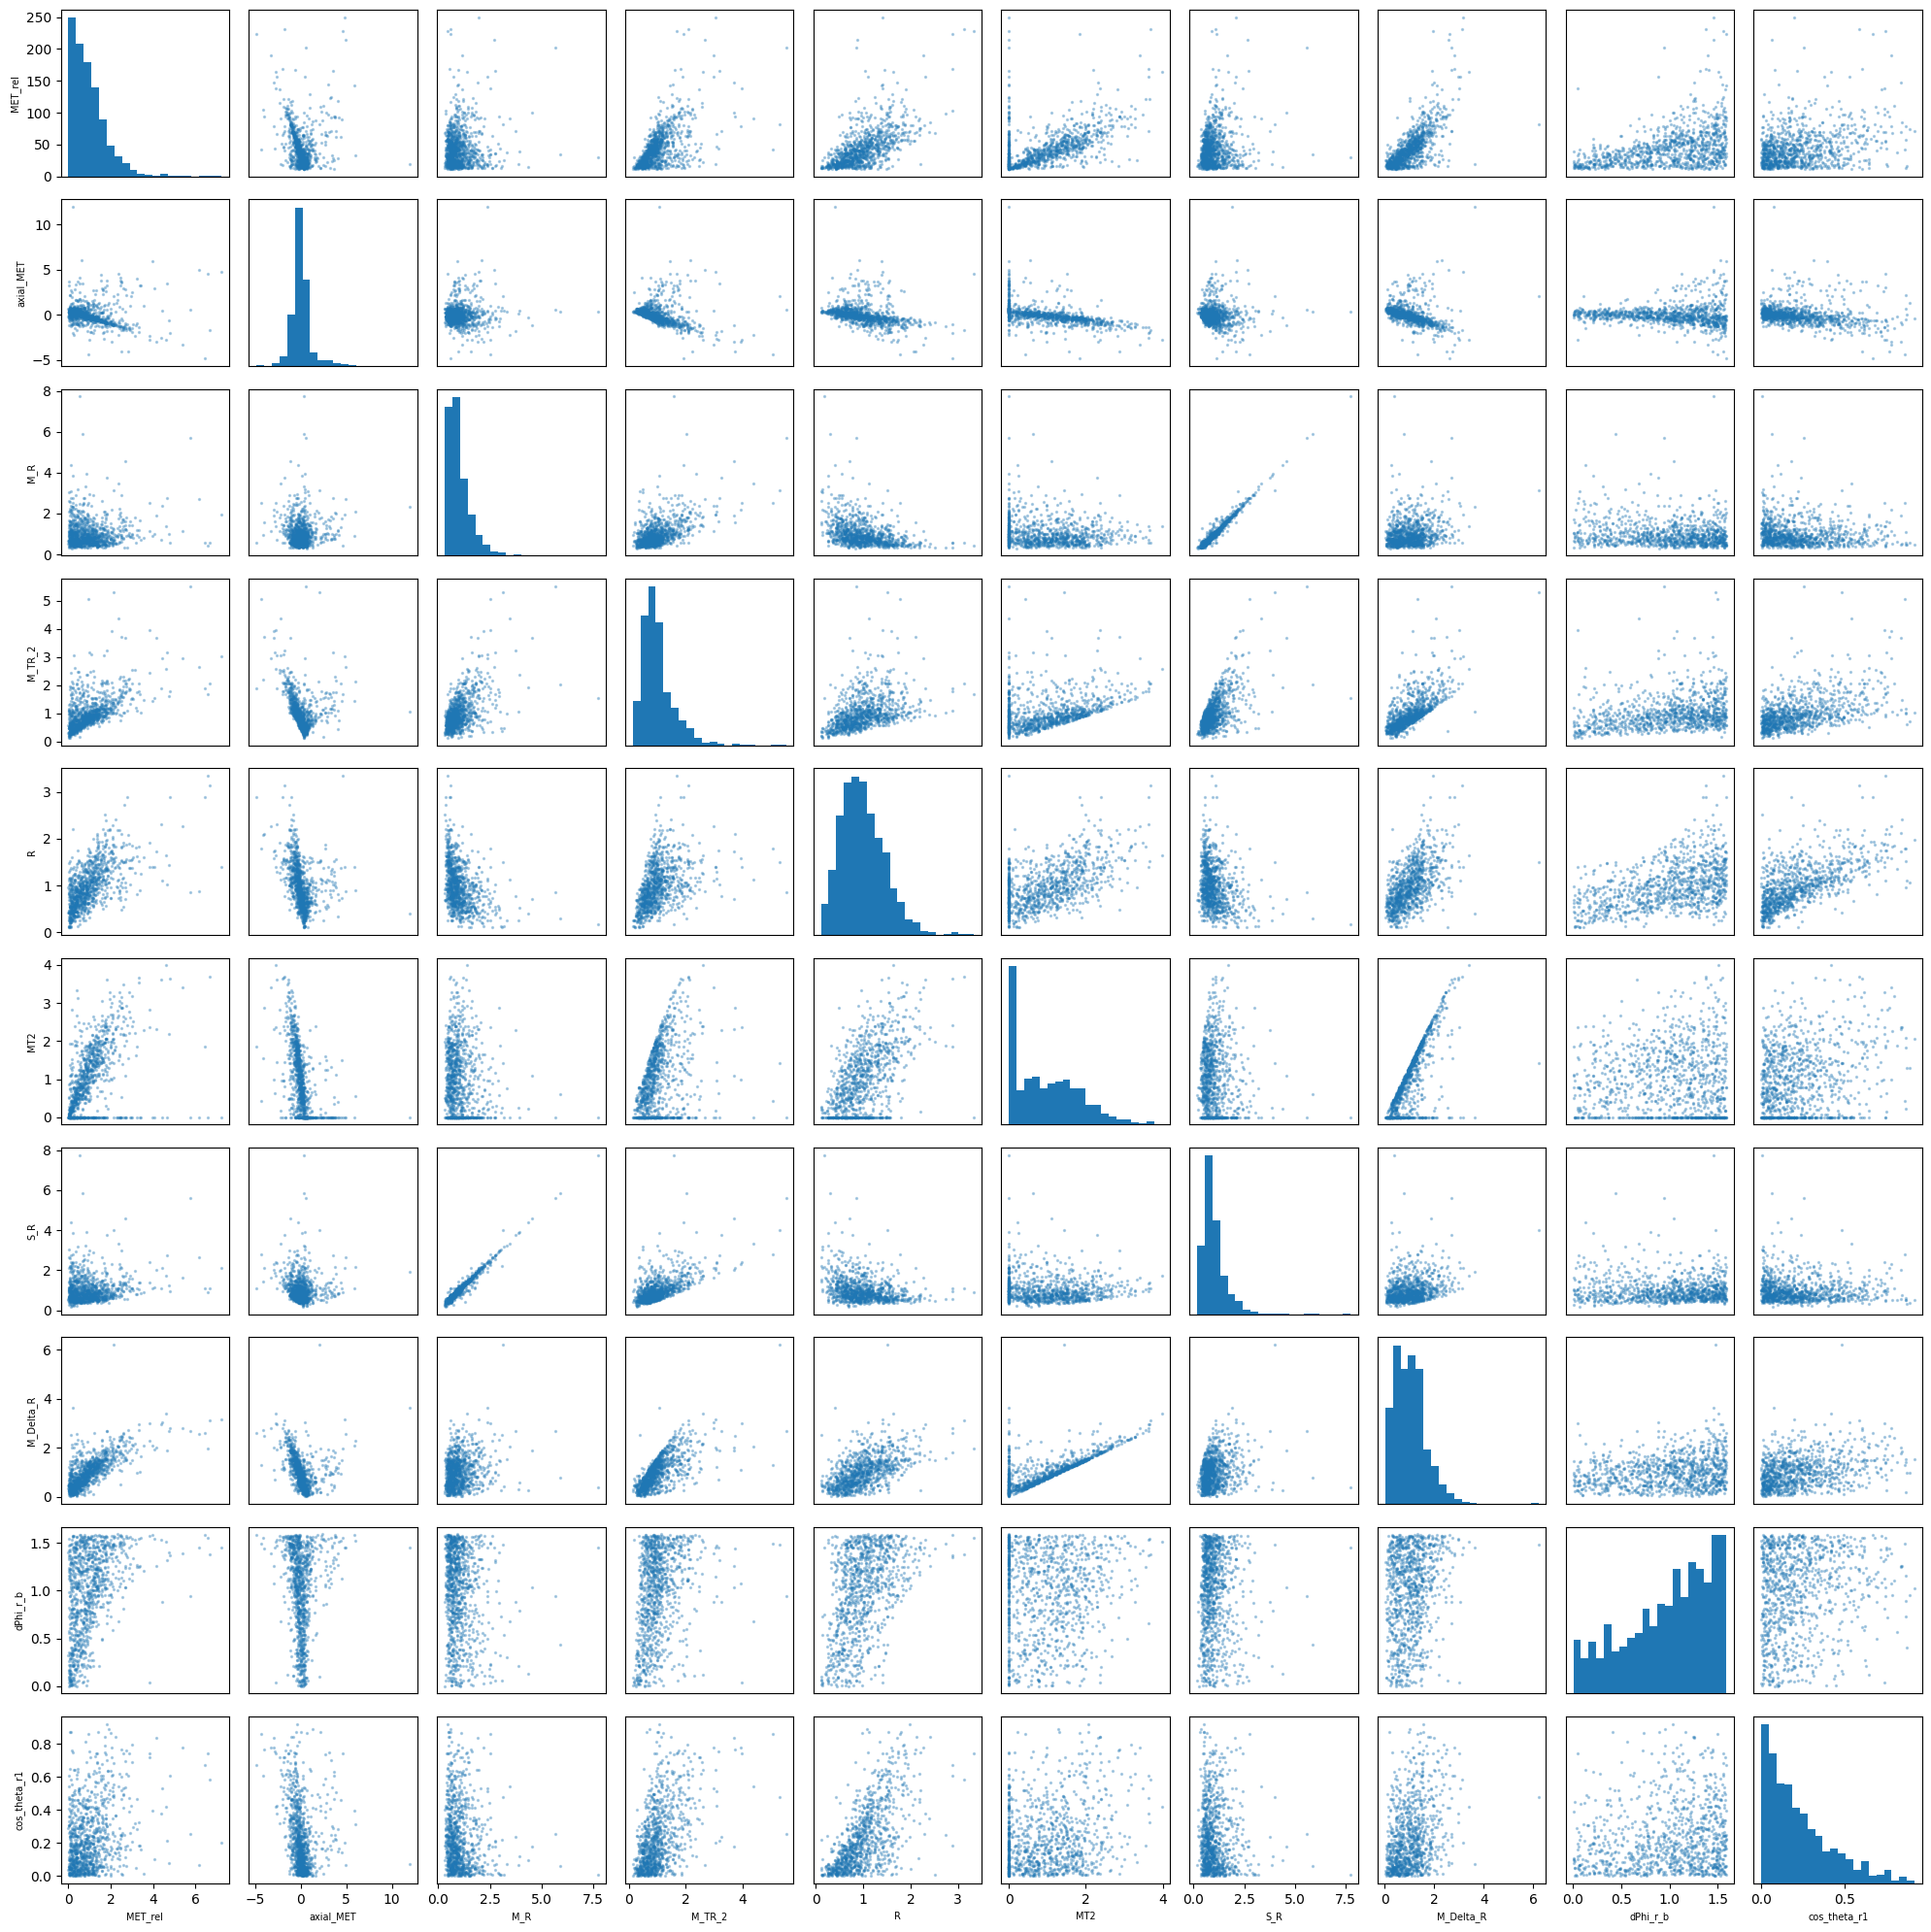

In [5]:
#4.1a
small = df.sample(n=min(1000, len(df)), random_state=1)

def pair_plots(data, names):
    count = len(names)
    fig, axes = plt.subplots(count, count, figsize=(2 * count, 2 * count))
    for i in range(count):
        for j in range(count):
            ax = axes[i, j]
            if i == j:
                ax.hist(data[names[i]], bins=20)
            else:
                ax.scatter(data[names[j]], data[names[i]], s=2, alpha=0.3)
            if i == count - 1:
                ax.set_xlabel(names[j], fontsize=7)
            else:
                ax.set_xticks([])
            if j == 0:
                ax.set_ylabel(names[i], fontsize=7)
            else:
                ax.set_yticks([])
    plt.tight_layout()
    plt.show()

pair_plots(small, RawNames)
pair_plots(small, FeatureNames)

Speed improvement: use 1000 sampled events instead of all 500000 events.
Alternative: use np.histogram2d to compute 2D histogram counts before plotting.


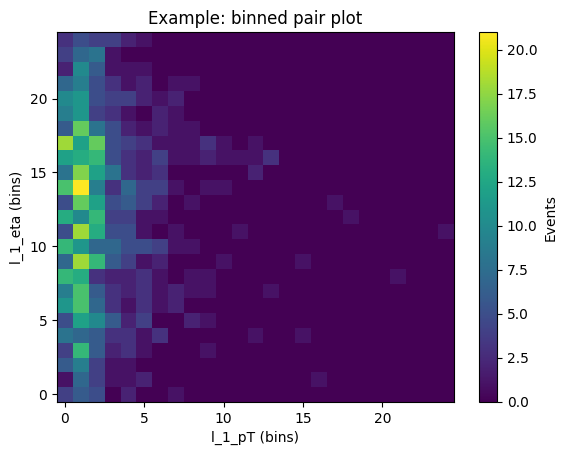

In [6]:
#4.1b
print("Speed improvement: use 1000 sampled events instead of all", len(df), "events.")
print("Alternative: use np.histogram2d to compute 2D histogram counts before plotting.")

counts, xedges, yedges = np.histogram2d(small[RawNames[0]], small[RawNames[1]], bins=25)
plt.imshow(counts.T, origin="lower", aspect="auto")
plt.xlabel(RawNames[0] + " (bins)")
plt.ylabel(RawNames[1] + " (bins)")
plt.title("Example: binned pair plot")
plt.colorbar(label="Events")
plt.show()

In [7]:
#4.1c
separation = {}
for name in VarNames[1:]:
    difference = abs(df_sig[name].mean() - df_bkg[name].mean())
    spread = df[name].std()
    separation[name] = difference / spread if spread > 0 else 0

ranking = sorted(separation, key=separation.get, reverse=True)
print("Best observables by a simple mean-separation score:")
for name in ranking[:5]:
    print(name, round(separation[name], 3))
print("This is one simple ranking. The significance and ROC exercises provide better comparisons.")

Best observables by a simple mean-separation score:
MET 0.882
M_TR_2 0.855
l_1_pT 0.785
MET_rel 0.568
M_Delta_R 0.55
This is one simple ranking. The significance and ROC exercises provide better comparisons.


In [8]:
#4.2a
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.


In [9]:
#4.2bcd
import tabulate
from IPython.display import HTML, display

def show_matrices(data, names, title):
    values = data[names].to_numpy()
    cov = np.cov(values, rowvar=False)
    corr = np.corrcoef(values, rowvar=False)

    print(title, "— Covariance matrix")
    rows = []
    for i in range(len(names)):
        rows.append([names[i]] + [round(float(x), 3) for x in cov[i]])
    display(HTML(tabulate.tabulate(rows, headers=["Variable"] + names, tablefmt="html")))

    print(title, "— Correlation matrix")
    rows = []
    for i in range(len(names)):
        rows.append([names[i]] + [round(float(x), 3) for x in corr[i]])
    display(HTML(tabulate.tabulate(rows, headers=["Variable"] + names, tablefmt="html")))
    return cov, corr

all_cov, all_corr = show_matrices(df, VarNames[1:], "All observables")
raw_cov, raw_corr = show_matrices(df, RawNames, "Low-level features")
feature_cov, feature_corr = show_matrices(df, FeatureNames, "High-level features")

All observables — Covariance matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


All observables — Correlation matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Low-level features — Covariance matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


... (2 outputs left out)

High-level features — Covariance matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


High-level features — Correlation matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


In [10]:
#5.1
work = df.sample(n=min(20000, len(df)), random_state=2)
scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]

def choose_events(values, cut, limit, mean):
    if cut == ">":
        return values > limit
    if cut == "<":
        return values < limit
    if cut == "outside":
        return abs(values - mean) > limit
    return abs(values - mean) < limit

def calculate_significance(tpr, fpr, ns, nb):
    s = ns * tpr
    b = nb * fpr
    if s + b == 0:
        return 0
    return s / np.sqrt(s + b)

cut_info = {}
for name in VarNames[1:]:
    values = work[name].to_numpy()
    signal = work["signal"].to_numpy() == 1
    mean = values.mean()
    best_score = -1

    for cut in [">", "<", "outside", "inside"]:
        if cut in ["outside", "inside"]:
            possible = np.quantile(abs(values - mean), np.linspace(0.02, 0.98, 35))
        else:
            possible = np.quantile(values, np.linspace(0.02, 0.98, 35))

        for limit in possible:
            passed = choose_events(values, cut, limit, mean)
            tpr = passed[signal].mean()
            fpr = passed[~signal].mean()
            score = calculate_significance(tpr, fpr, 1000, 10000)
            if score > best_score:
                best_score = score
                best_cut = cut
                best_limit = float(limit)

    cut_info[name] = {"cut": best_cut, "limit": best_limit, "mean": mean, "score": best_score}
    print(name, best_cut, "threshold =", round(best_limit, 3))

l_1_pT > threshold = 0.858
l_1_eta inside threshold = 1.413
l_1_phi inside threshold = 1.701
l_2_pT > threshold = 0.443
l_2_eta inside threshold = 1.646
l_2_phi > threshold = -1.661
MET > threshold = 1.508
MET_phi > threshold = -1.656
MET_rel > threshold = 2.236
axial_MET outside threshold = 1.347
M_R > threshold = 0.709
M_TR_2 > threshold = 1.342
R > threshold = 0.259
MT2 outside threshold = 0.026
S_R > threshold = 0.692
M_Delta_R > threshold = 0.098
dPhi_r_b < threshold = 1.574
cos_theta_r1 > threshold = 0.019


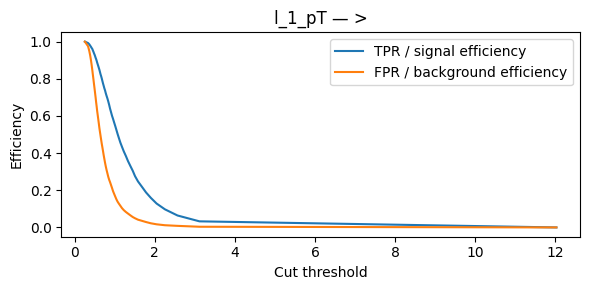

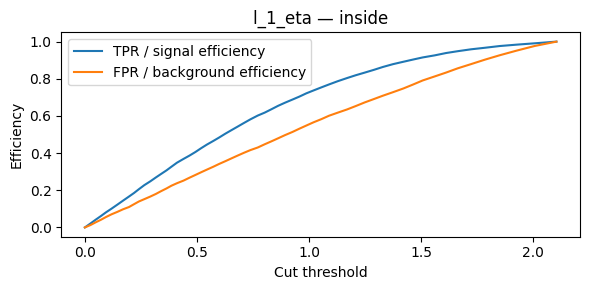

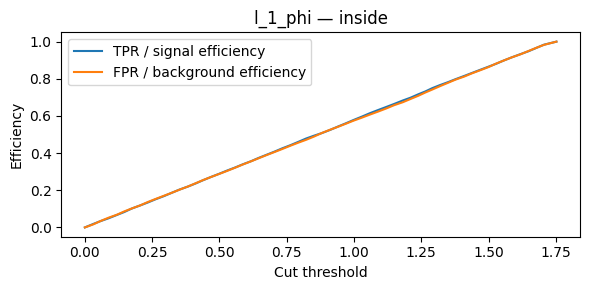

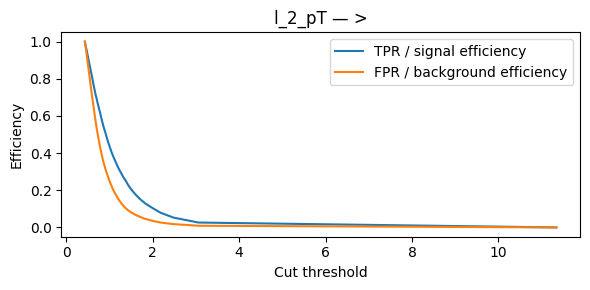

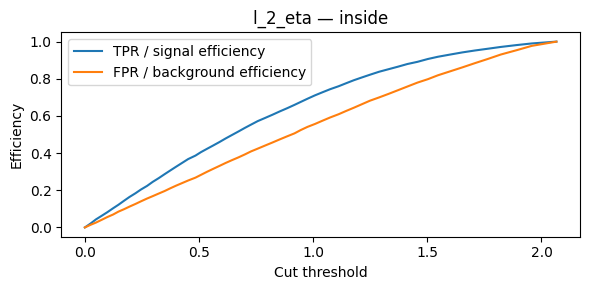

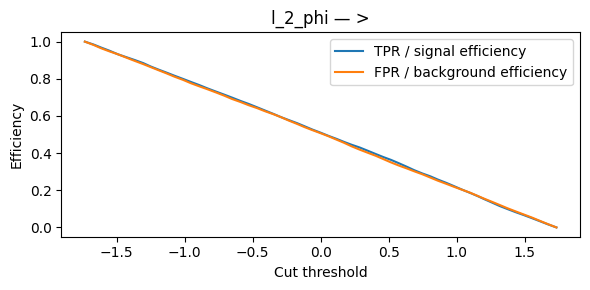

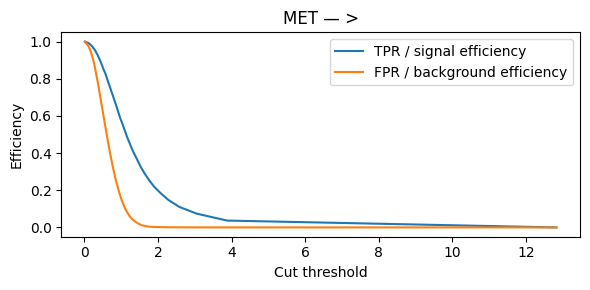

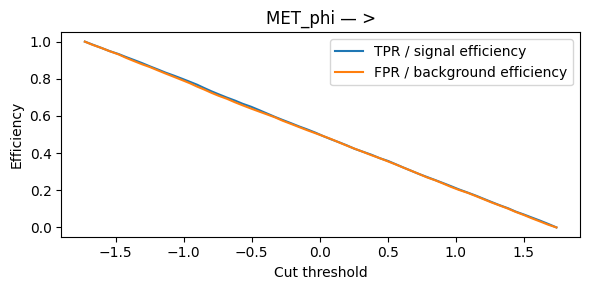

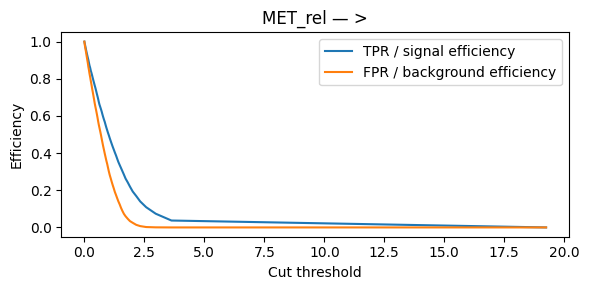

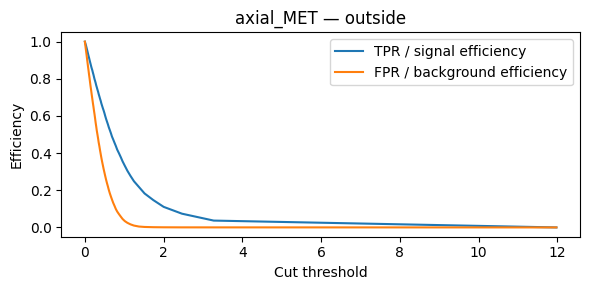

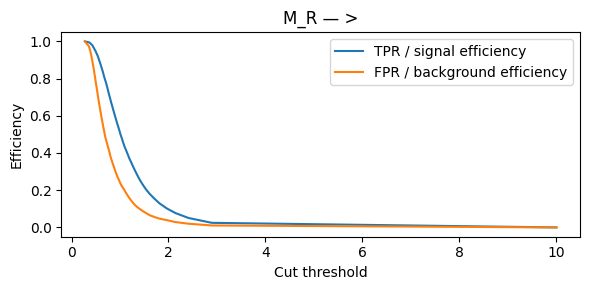

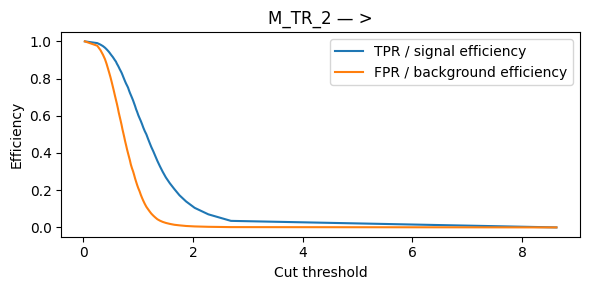

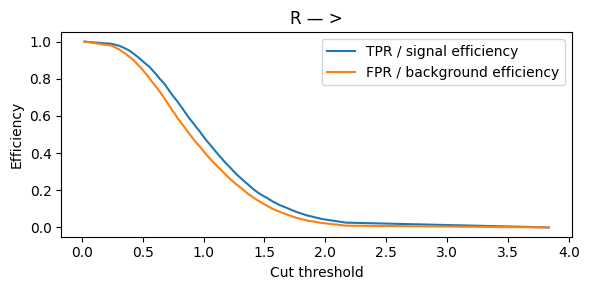

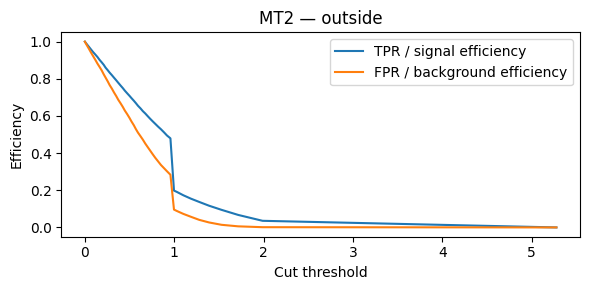

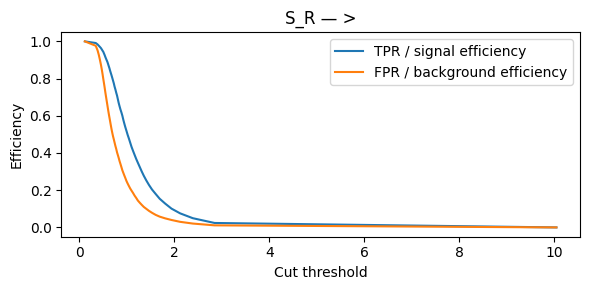

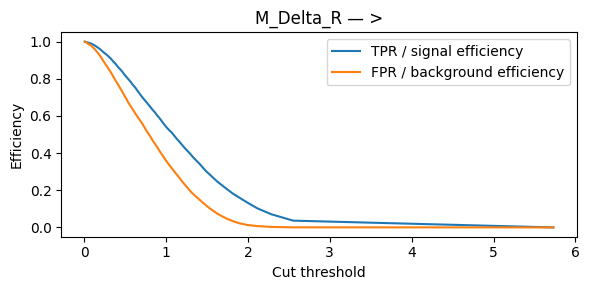

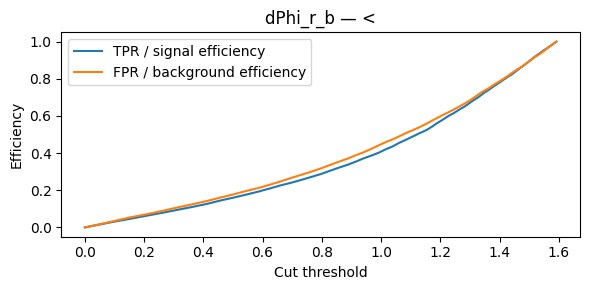

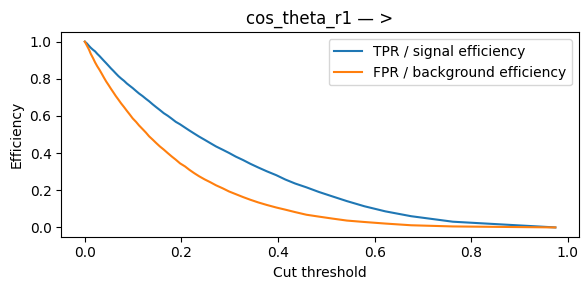

In [11]:
#5.2
curves = {}
signal = work["signal"].to_numpy() == 1

for name in VarNames[1:]:
    values = work[name].to_numpy()
    cut = cut_info[name]["cut"]
    mean = cut_info[name]["mean"]
    data_for_threshold = abs(values - mean) if cut in ["outside", "inside"] else values
    limits = np.quantile(data_for_threshold, np.linspace(0, 1, 60))
    tprs = []
    fprs = []

    for limit in limits:
        passed = choose_events(values, cut, limit, mean)
        tprs.append(passed[signal].mean())
        fprs.append(passed[~signal].mean())

    curves[name] = {"limits": limits, "tpr": np.array(tprs), "fpr": np.array(fprs)}

    plt.figure(figsize=(6, 3))
    plt.plot(limits, tprs, label="TPR / signal efficiency")
    plt.plot(limits, fprs, label="FPR / background efficiency")
    plt.xlabel("Cut threshold")
    plt.ylabel("Efficiency")
    plt.title(name + " — " + cut)
    plt.legend()
    plt.tight_layout()
    plt.show()

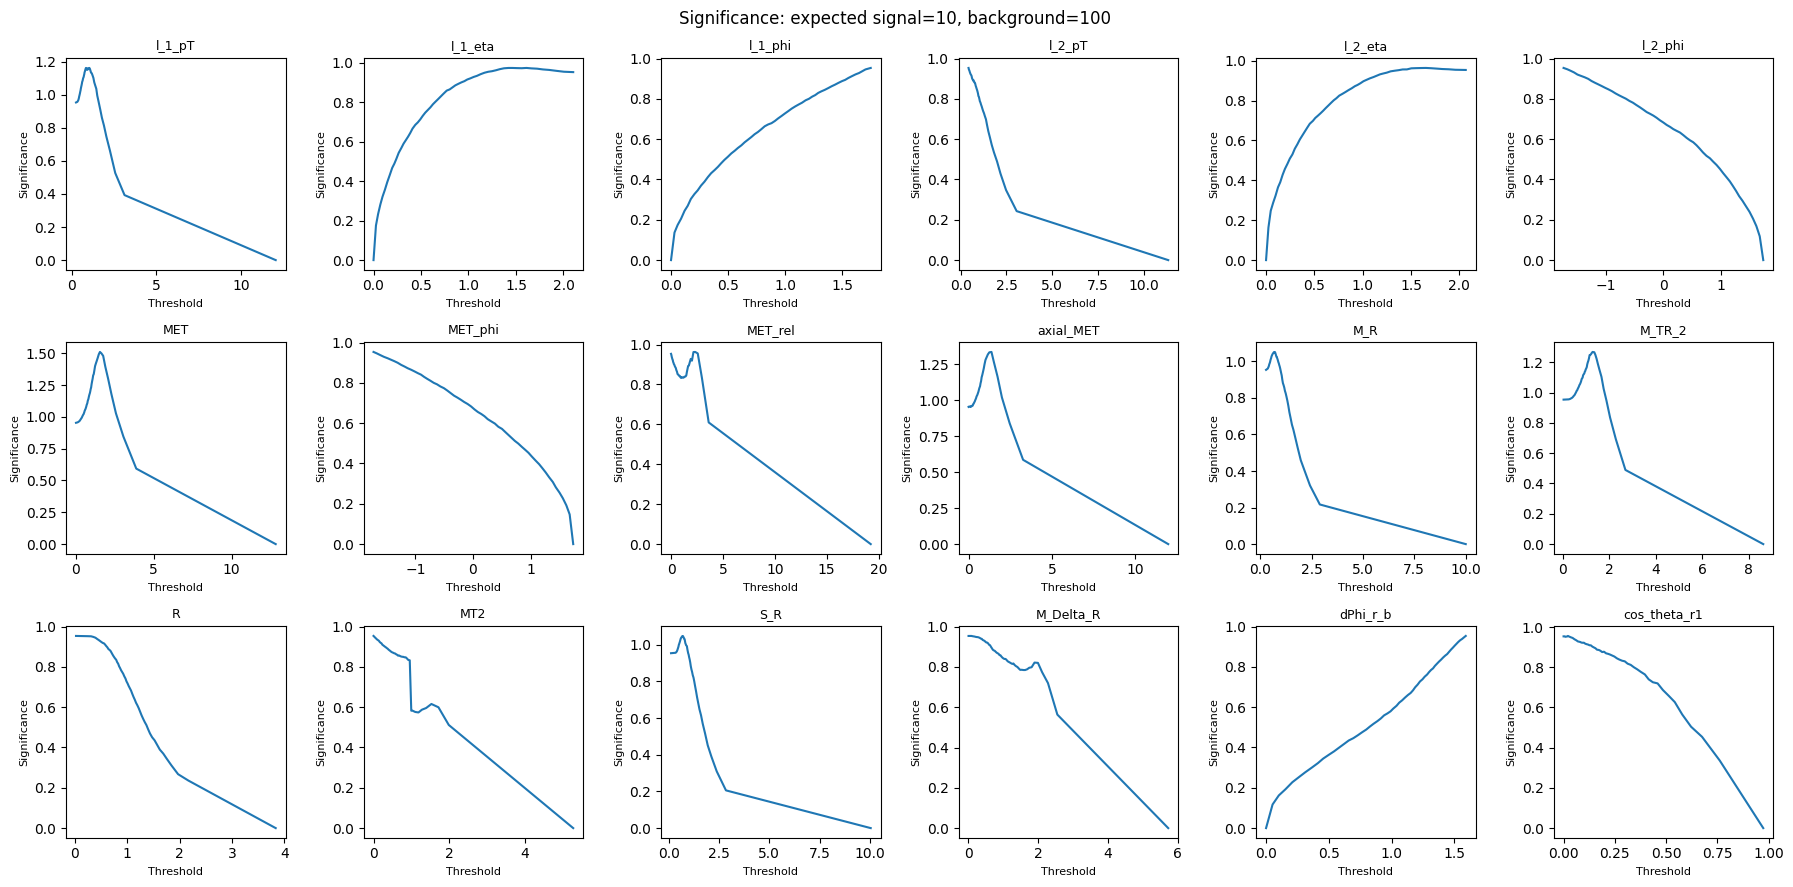

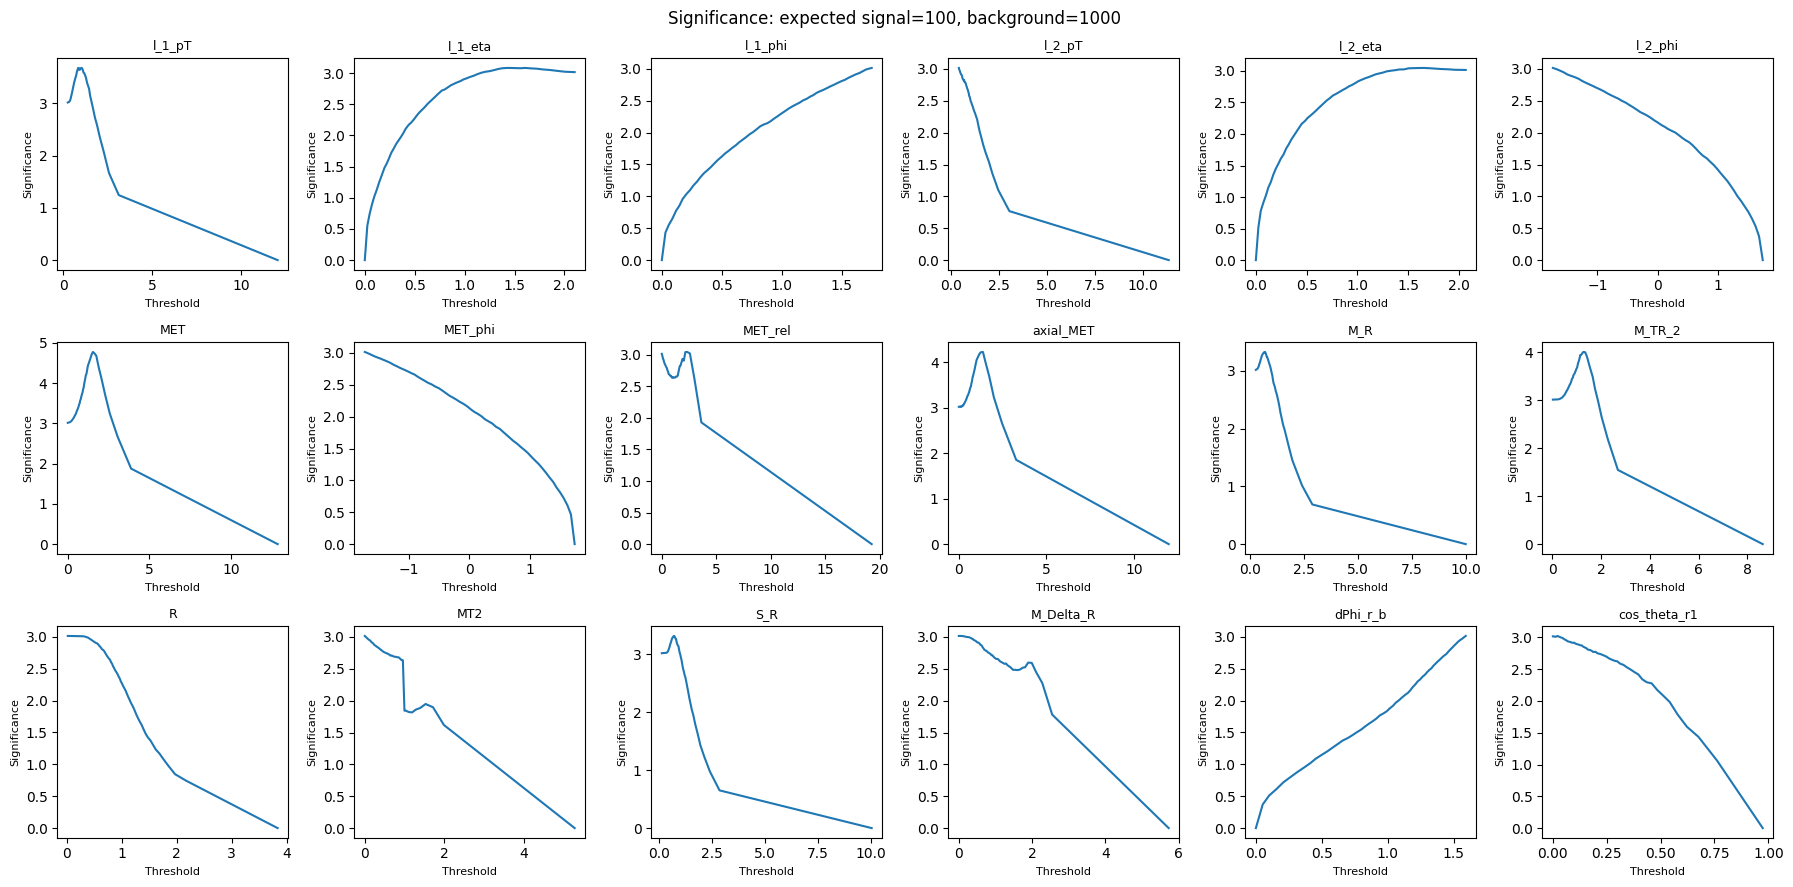

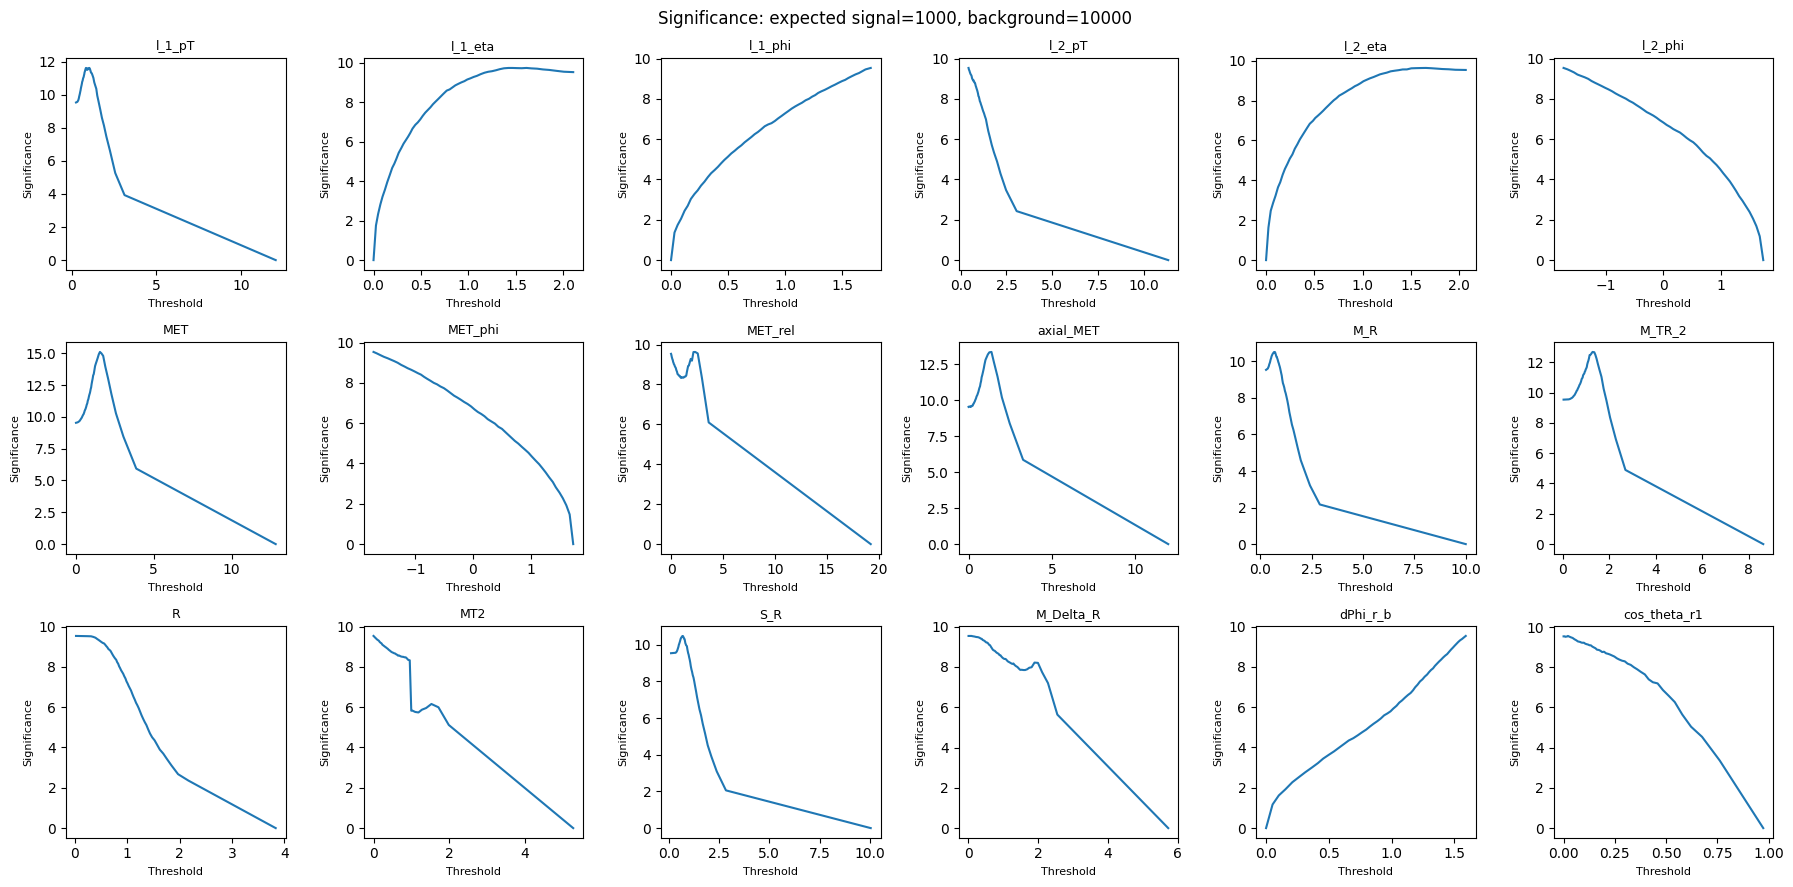

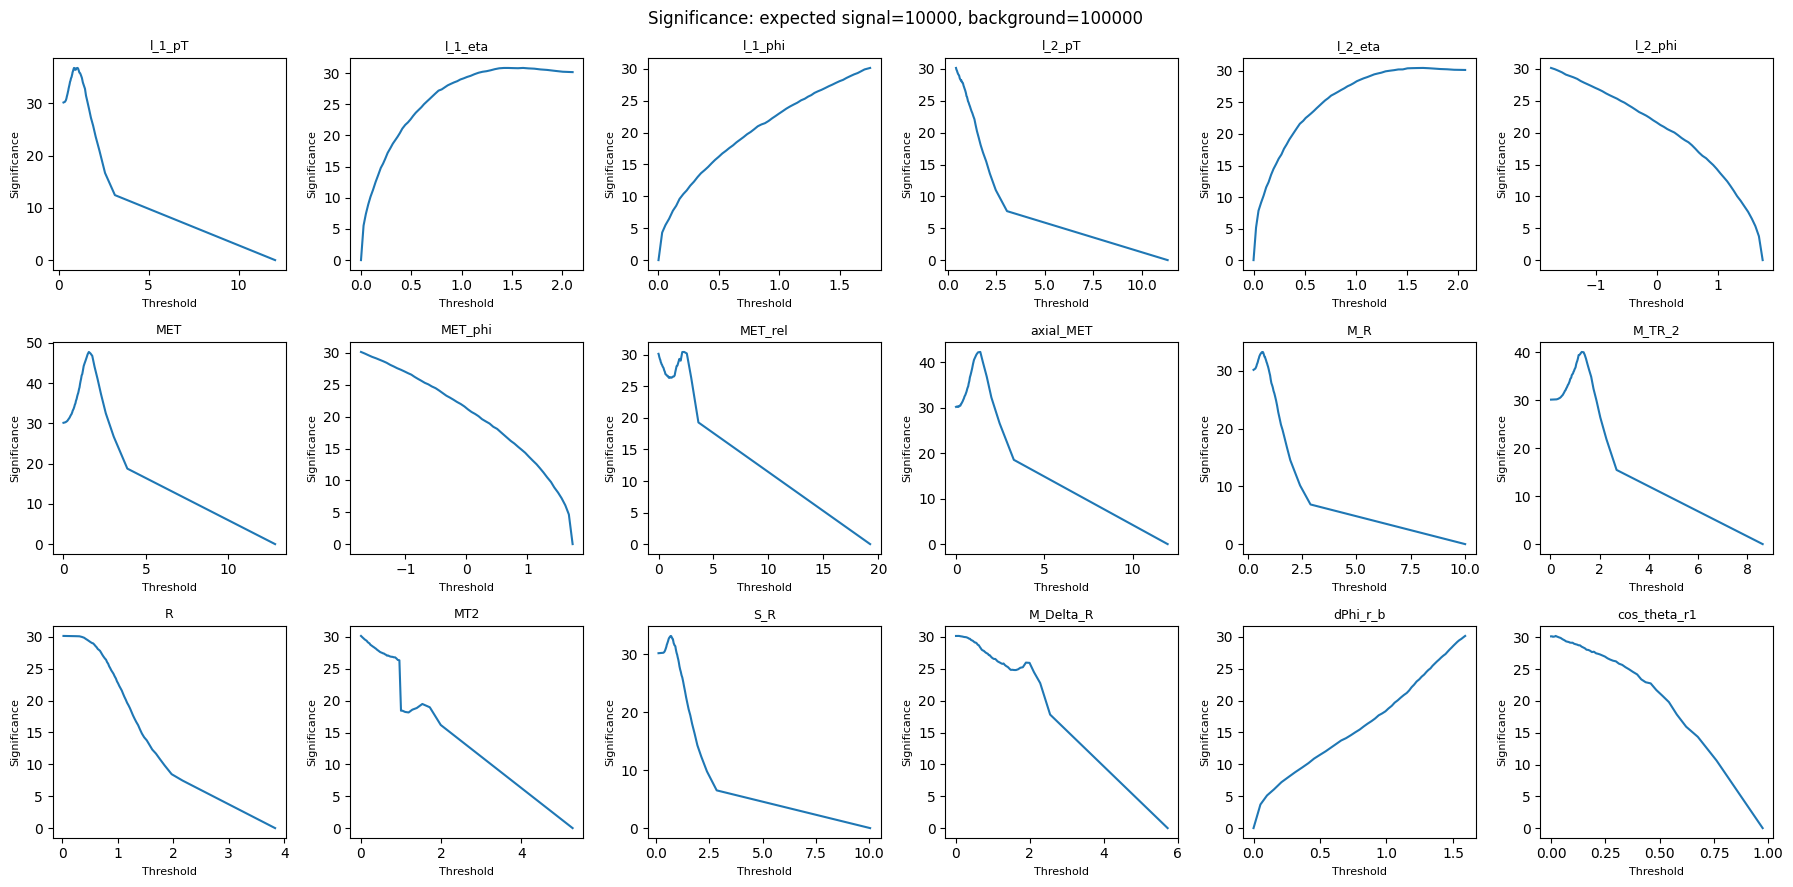

In [12]:
#5.3
for ns, nb in scenarios:
    fig, axes = plt.subplots(3, 6, figsize=(18, 9))
    for i, name in enumerate(VarNames[1:]):
        values = curves[name]
        s = ns * values["tpr"]
        b = nb * values["fpr"]
        significance = np.divide(s, np.sqrt(s + b), out=np.zeros_like(s), where=(s + b) > 0)
        ax = axes.flat[i]
        ax.plot(values["limits"], significance)
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("Threshold", fontsize=8)
        ax.set_ylabel("Significance", fontsize=8)
    fig.suptitle("Significance: expected signal=" + str(ns) + ", background=" + str(nb))
    plt.tight_layout()
    plt.show()

In [13]:
#6.1
best_three = sorted(cut_info, key=lambda name: cut_info[name]["score"], reverse=True)[:3]
print("Three selected observables:")
for name in best_three:
    info = cut_info[name]
    print(name, info["cut"], round(info["limit"], 3))

Three selected observables:
MET > 1.508
axial_MET outside 1.347
M_TR_2 > 1.342


In [15]:
#6.2
for ns, nb in scenarios:
    remaining = np.ones(len(work), dtype=bool)
    rows = []
    label = work["signal"].to_numpy() == 1
    rows.append(["No cuts", 1.0, 1.0, ns, nb, calculate_significance(1, 1, ns, nb)])

    for name in best_three:
        info = cut_info[name]
        remaining = remaining & choose_events(work[name].to_numpy(), info["cut"], info["limit"], info["mean"])
        es = remaining[label].mean()
        eb = remaining[~label].mean()
        rows.append([name, es, eb, ns * es, nb * eb, calculate_significance(es, eb, ns, nb)])

    print("Cut flow: NS =", ns, "NB =", nb)
    pretty = [[row[0]] + [round(x, 4) for x in row[1:]] for row in rows]
    display(HTML(tabulate.tabulate(pretty, headers=["Selection", "eff_S", "eff_B", "N_S'", "N_B'", "Significance"], tablefmt="html")))

Cut flow: NS = 10 NB = 100


Selection,eff_S,eff_B,N_S',N_B',Significance
No cuts,1,1,10,100,0.9535
MET,0.3348,0.0157,3.3483,1.5714,1.5096
axial_MET,0.2016,0.0045,2.0158,0.4503,1.2836
M_TR_2,0.1361,0.0036,1.361,0.3584,1.038


Cut flow: NS = 100 NB = 1000


Selection,eff_S,eff_B,N_S',N_B',Significance
No cuts,1,1,100,1000,3.0151
MET,0.3348,0.0157,33.4832,15.714,4.7737
axial_MET,0.2016,0.0045,20.1579,4.5028,4.0592
M_TR_2,0.1361,0.0036,13.6104,3.5839,3.2823


Cut flow: NS = 1000 NB = 10000


Selection,eff_S,eff_B,N_S',N_B',Significance
No cuts,1,1,1000,10000,9.5346
MET,0.3348,0.0157,334.832,157.14,15.0958
axial_MET,0.2016,0.0045,201.579,45.0285,12.8364
M_TR_2,0.1361,0.0036,136.104,35.839,10.3796


Cut flow: NS = 10000 NB = 100000


Selection,eff_S,eff_B,N_S',N_B',Significance
No cuts,1,1,10000,100000,30.1511
MET,0.3348,0.0157,3348.32,1571.4,47.7372
axial_MET,0.2016,0.0045,2015.79,450.285,40.5922
M_TR_2,0.1361,0.0036,1361.04,358.39,32.8231


In [16]:
#6.3
names = VarNames[1:]
most_correlated = 0
first_name = names[0]
second_name = names[1]

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        value = abs(all_corr[i, j])
        if value > most_correlated:
            most_correlated = value
            first_name = names[i]
            second_name = names[j]

print("Most strongly correlated pair:", first_name, "and", second_name)
print("Absolute correlation:", round(most_correlated, 3))

def optimize_second(first, second):
    label = work["signal"].to_numpy() == 1
    a = cut_info[first]
    mask_first = choose_events(work[first].to_numpy(), a["cut"], a["limit"], a["mean"])
    b = cut_info[second]
    values = work[second].to_numpy()
    choices = abs(values - b["mean"]) if b["cut"] in ["outside", "inside"] else values
    limits = np.quantile(choices, np.linspace(0.02, 0.98, 50))
    best_score = -1
    best_limit = None

    for limit in limits:
        mask_second = choose_events(values, b["cut"], limit, b["mean"])
        selected = mask_first & mask_second
        es = selected[label].mean()
        eb = selected[~label].mean()
        score = calculate_significance(es, eb, 1000, 10000)
        if score > best_score:
            best_score = score
            best_limit = limit

    print(first, "then", second, "optimized threshold:", round(float(best_limit), 3), "significance:", round(best_score, 4))
    return best_limit, best_score

limit_ab, score_ab = optimize_second(first_name, second_name)
limit_ba, score_ba = optimize_second(second_name, first_name)
print("For identical fixed cuts, changing their order does not change the final selected events.")
print("Reoptimizing the second cut can change the final result.")

Most strongly correlated pair: M_R and S_R
Absolute correlation: 0.981
M_R then S_R optimized threshold: 0.35 significance: 10.4992
S_R then M_R optimized threshold: 0.366 significance: 10.4805
For identical fixed cuts, changing their order does not change the final selected events.
Reoptimizing the second cut can change the final result.


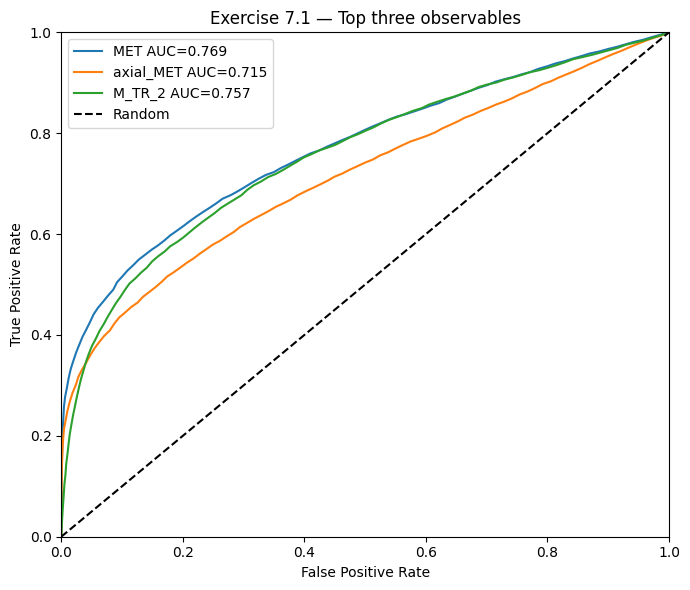

AUC values: {'MET': np.float64(0.7693213353044538), 'axial_MET': np.float64(0.714933917528595), 'M_TR_2': np.float64(0.7567017293611151)}


In [17]:
#7.1 and 7.2
def roc_plot(data, names, title, preselection=None):
    label = data["signal"].to_numpy() == 1
    if preselection is None:
        preselection = np.ones(len(data), dtype=bool)

    plt.figure(figsize=(7, 6))
    results = {}
    for name in names:
        values = data[name].to_numpy()
        info = cut_info[name]
        cut = info["cut"]
        mean = info["mean"]
        amount = abs(values - mean) if cut in ["outside", "inside"] else values
        limits = np.quantile(amount, np.linspace(0, 1, 101))
        tpr = [0.0]
        fpr = [0.0]

        for limit in limits:
            passed = preselection & choose_events(values, cut, limit, mean)
            tpr.append(passed[label].mean())
            fpr.append(passed[~label].mean())

        tpr.append(float(preselection[label].mean()))
        fpr.append(float(preselection[~label].mean()))
        order = np.argsort(fpr)
        sorted_fpr = np.array(fpr)[order]
        sorted_tpr = np.array(tpr)[order]
        auc = np.trapezoid(sorted_tpr, sorted_fpr) if hasattr(np, "trapezoid") else np.trapz(sorted_tpr, sorted_fpr)
        plt.plot(sorted_fpr, sorted_tpr, label=name + " AUC=" + str(round(auc, 3)))
        results[name] = auc

    plt.plot([0, 1], [0, 1], "k--", label="Random")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return results

auc_results = roc_plot(work, best_three, "Exercise 7.1 — Top three observables")
print("AUC values:", auc_results)

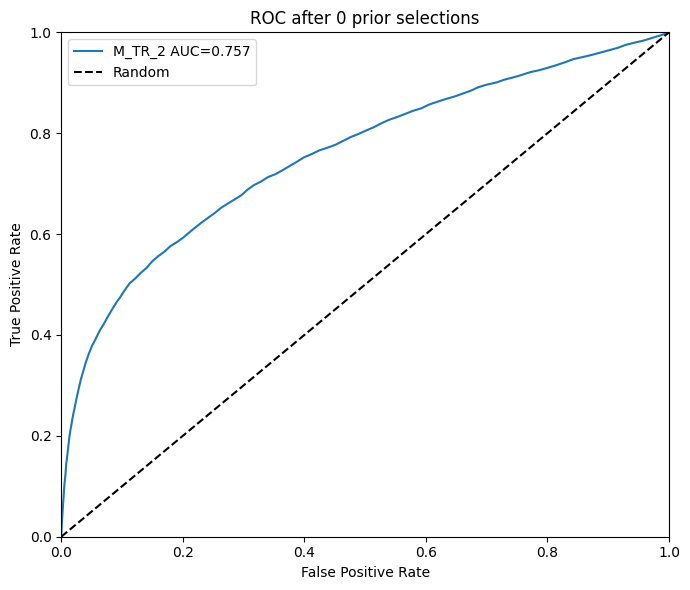

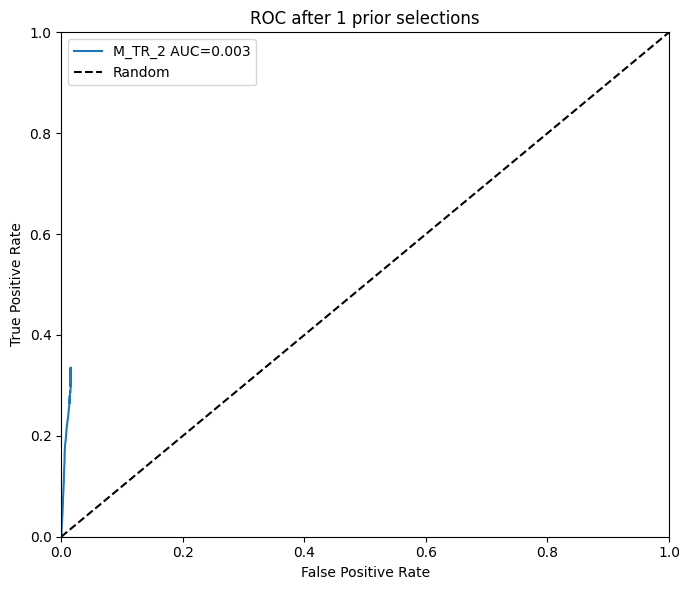

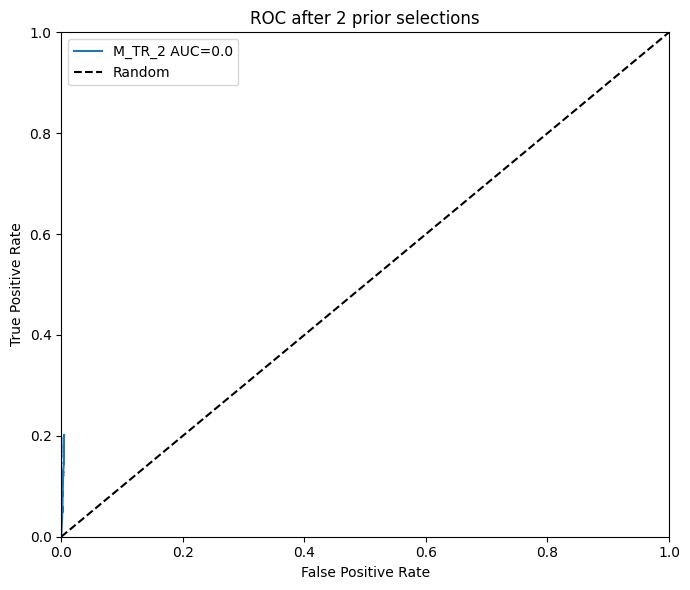

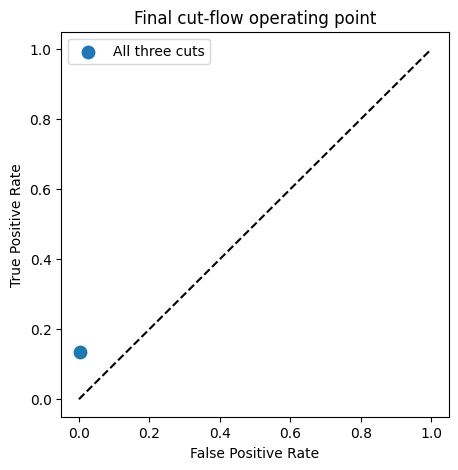

In [18]:
#7.3
label = work["signal"].to_numpy() == 1
mask = np.ones(len(work), dtype=bool)

for i in range(len(best_three)):
    roc_plot(work, [best_three[-1]], "ROC after " + str(i) + " prior selections", mask)
    name = best_three[i]
    info = cut_info[name]
    mask = mask & choose_events(work[name].to_numpy(), info["cut"], info["limit"], info["mean"])

final_tpr = mask[label].mean()
final_fpr = mask[~label].mean()
plt.figure(figsize=(5, 5))
plt.scatter([final_fpr], [final_tpr], s=80, label="All three cuts")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final cut-flow operating point")
plt.legend()
plt.show()

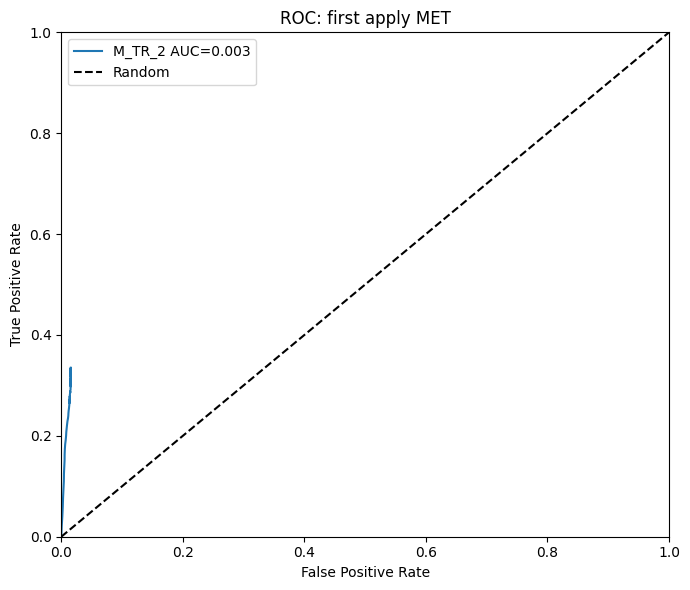

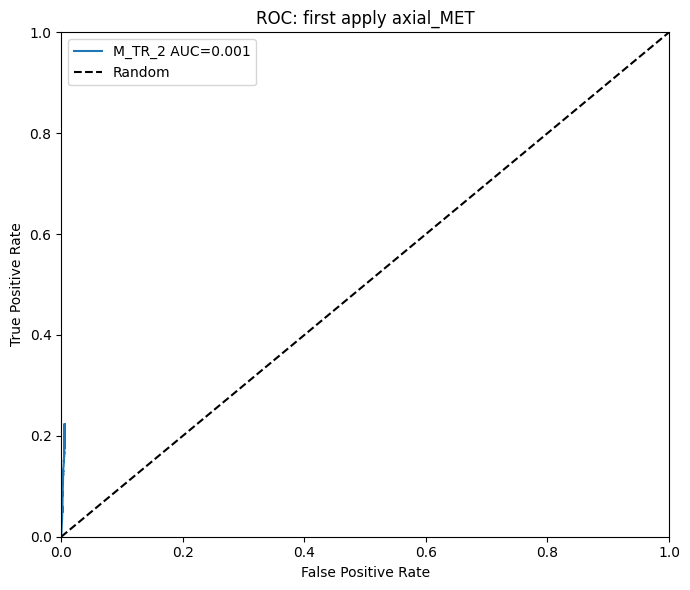

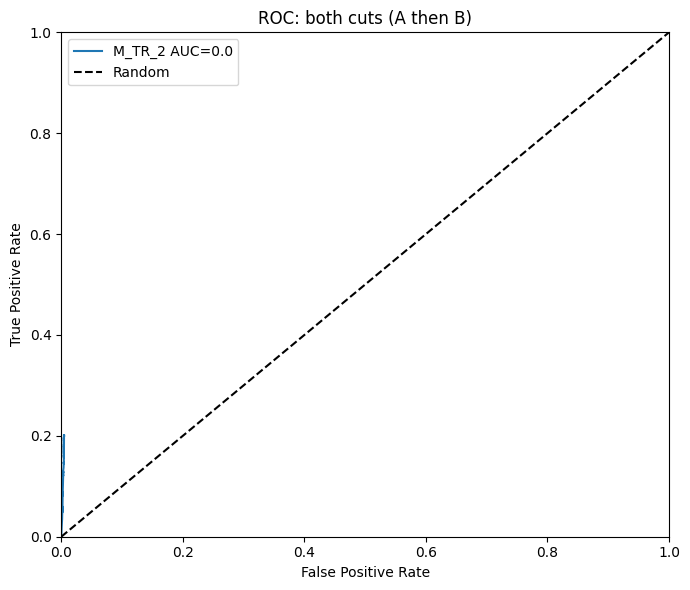

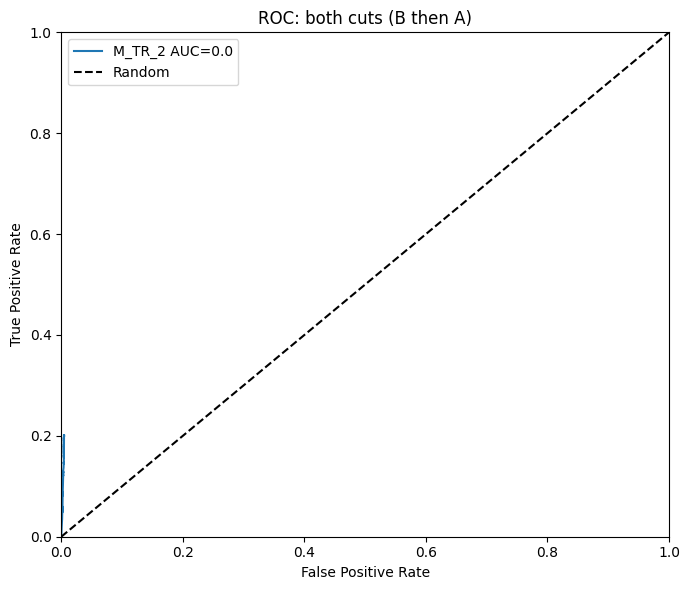

Same final selected events after both fixed cuts: True


In [19]:
#7.4
first = best_three[0]
second = best_three[1]
third = best_three[2]

info_a = cut_info[first]
info_b = cut_info[second]

mask_a = choose_events(work[first].to_numpy(), info_a["cut"], info_a["limit"], info_a["mean"])
mask_b = choose_events(work[second].to_numpy(), info_b["cut"], info_b["limit"], info_b["mean"])

roc_plot(work, [third], "ROC: first apply " + first, mask_a)
roc_plot(work, [third], "ROC: first apply " + second, mask_b)
roc_plot(work, [third], "ROC: both cuts (A then B)", mask_a & mask_b)
roc_plot(work, [third], "ROC: both cuts (B then A)", mask_b & mask_a)
print("Same final selected events after both fixed cuts:", np.array_equal(mask_a & mask_b, mask_b & mask_a))

In [20]:
#8.1
names = VarNames[1:]
x_sig = work[work["signal"] == 1][names].to_numpy()
x_bkg = work[work["signal"] == 0][names].to_numpy()

m1 = x_sig.mean(axis=0)
m2 = x_bkg.mean(axis=0)
difference = m2 - m1

SB = np.outer(difference, difference)
centered_sig = x_sig - m1
centered_bkg = x_bkg - m2
SW = centered_sig.T @ centered_sig + centered_bkg.T @ centered_bkg

print("Between-class matrix shape:", SB.shape)
print("Within-class matrix shape:", SW.shape)
print("Between-class matrix:")
print(np.round(SB, 3))
print("Within-class matrix:")
print(np.round(SW, 3))

Between-class matrix shape: (18, 18)
Within-class matrix shape: (18, 18)
Between-class matrix:
[[ 0.277  0.003 -0.002  0.136 -0.007  0.007  0.402  0.006  0.265  0.086
   0.175  0.258  0.053  0.067  0.168  0.175  0.015  0.054]
 [ 0.003  0.    -0.     0.001 -0.     0.     0.004  0.     0.003  0.001
   0.002  0.002  0.001  0.001  0.002  0.002  0.     0.001]
 [-0.002 -0.     0.    -0.001  0.    -0.    -0.003 -0.    -0.002 -0.001
  -0.001 -0.002 -0.    -0.001 -0.001 -0.001 -0.    -0.   ]
 [ 0.136  0.001 -0.001  0.067 -0.003  0.003  0.197  0.003  0.13   0.042
   0.086  0.126  0.026  0.033  0.083  0.086  0.007  0.027]
 [-0.007 -0.     0.    -0.003  0.    -0.    -0.01  -0.    -0.006 -0.002
  -0.004 -0.006 -0.001 -0.002 -0.004 -0.004 -0.    -0.001]
 [ 0.007  0.    -0.     0.003 -0.     0.     0.01   0.     0.006  0.002
   0.004  0.006  0.001  0.002  0.004  0.004  0.     0.001]
 [ 0.402  0.004 -0.003  0.197 -0.01   0.01   0.581  0.009  0.383  0.125
   0.254  0.373  0.077  0.097  0.244  0.254  0.

Fisher coefficients:
l_1_pT -6.04e-05
l_1_eta -2e-07
l_1_phi -8e-07
l_2_pT -2.65e-05
l_2_eta 9e-07
l_2_phi -3e-07
MET -4.4e-05
MET_phi -7e-07
MET_rel 5e-07
axial_MET -7.7e-06
M_R 1.13e-05
M_TR_2 -1.8e-06
R 5.47e-05
MT2 6.4e-06
S_R 4.41e-05
M_Delta_R -4.36e-05
dPhi_r_b -4e-07
cos_theta_r1 -0.0001283


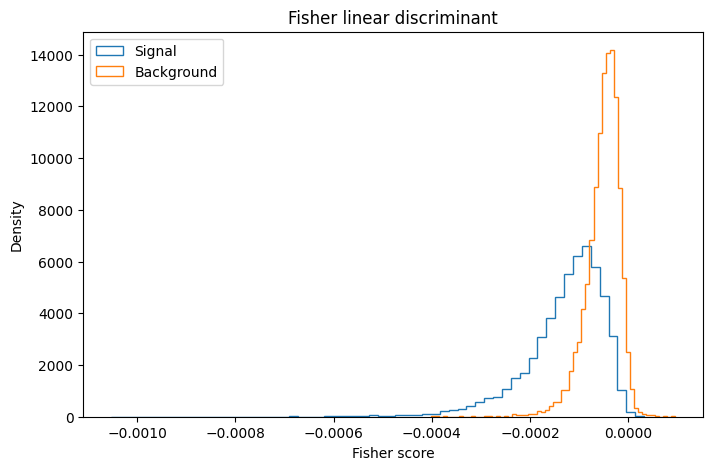

In [21]:
#8.2
w = np.linalg.pinv(SW) @ difference
sig_scores = x_sig @ w
bkg_scores = x_bkg @ w

print("Fisher coefficients:")
for i in range(len(names)):
    print(names[i], round(w[i], 7))

plt.figure(figsize=(8, 5))
plt.hist(sig_scores, bins=60, density=True, histtype="step", label="Signal")
plt.hist(bkg_scores, bins=60, density=True, histtype="step", label="Background")
plt.xlabel("Fisher score")
plt.ylabel("Density")
plt.title("Fisher linear discriminant")
plt.legend()
plt.show()

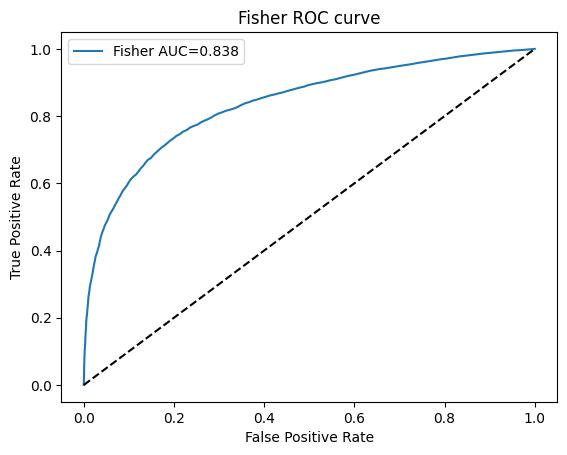

In [22]:
#8.3
all_scores = np.concatenate([sig_scores, bkg_scores])
limits = np.quantile(all_scores, np.linspace(0, 1, 150))

if sig_scores.mean() > bkg_scores.mean():
    compare = ">"
else:
    compare = "<"

fisher_tpr = [0.0]
fisher_fpr = [0.0]
for limit in limits:
    if compare == ">":
        fisher_tpr.append(float(np.mean(sig_scores > limit)))
        fisher_fpr.append(float(np.mean(bkg_scores > limit)))
    else:
        fisher_tpr.append(float(np.mean(sig_scores < limit)))
        fisher_fpr.append(float(np.mean(bkg_scores < limit)))

fisher_tpr.append(1.0)
fisher_fpr.append(1.0)
order = np.argsort(fisher_fpr)
fisher_auc = np.trapezoid(np.array(fisher_tpr)[order], np.array(fisher_fpr)[order]) if hasattr(np, "trapezoid") else np.trapz(np.array(fisher_tpr)[order], np.array(fisher_fpr)[order])

plt.plot(np.array(fisher_fpr)[order], np.array(fisher_tpr)[order], label="Fisher AUC=" + str(round(fisher_auc, 3)))
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fisher ROC curve")
plt.legend()
plt.show()

In [24]:
#8.4
for ns, nb in scenarios:
    scores = []
    for i in range(len(fisher_tpr)):
        scores.append(calculate_significance(fisher_tpr[i], fisher_fpr[i], ns, nb))
    print("NS =", ns, "NB =", nb, "Max significance =", round(max(scores), 4))

NS = 10 NB = 100 Max significance = 1.5479
NS = 100 NB = 1000 Max significance = 4.895
NS = 1000 NB = 10000 Max significance = 15.4794
NS = 10000 NB = 100000 Max significance = 48.9501
